# **2. Motivos de Cartão e Detecção de VAR: Embeddings, BERTopic e Rotulagem Semântica**

**Alunos:**
- Gabriel Carbinatto (12725411)
- Arthur Martins (14783601)

Este notebook implementa um pipeline de NLP para analisar justificativas livres de cartões amarelos e vermelhos e motivos de acréscimos nas súmulas do Campeonato Brasileiro. O objetivo é agrupar semanticamente os motivos de cartão e detectar menções textuais ao VAR nos acréscimos.

**Cartões:** identificar o tipo de falta por trás de cada cartão, caracterizando o perfil de marcação de cada árbitro e o padrão de infrações de cada time.

**Acréscimos/atrasos:** detectar, de forma binária, se há menção ao VAR na justificativa registrada pelo árbitro.

## **Pipeline de Motivos de Cartão**

1. **Embeddings base** — `multilingual-e5-large` aplicado ao conjunto de textos únicos de justificativas, com prefixos `passage:` / `query:` conforme protocolo E5.
2. **Seleção de hiperparâmetros** — grid search sobre `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN), avaliado por DBCV no espaço reduzido.
3. **BERTopic — Passagem 1** — clustering exploratório com o modelo base; gera pares positivos para o fine-tuning.
4. **Fine-tuning** — `MultipleNegativesRankingLoss` com pares derivados dos clusters da Passagem 1.
5. **BERTopic — Passagem 2** — clusters finais com embeddings do modelo fine-tunado.
6. **Ablação** — comparação entre Passagem 1 e Passagem 2 em número de clusters, taxa de outliers e DBCV.
7. **Rotulagem semântica manual** — taxonomia fixa, mapeamento manual dos clusters e mapeamento manual dos outliers HDBSCAN.
8. **Diagnóstico de representatividade** — similaridade cosseno entre cada texto e o centroide ponderado do grupo.

---

## **1. Bibliotecas**

- `sentence-transformers` — embeddings semânticos e fine-tuning com `MultipleNegativesRankingLoss`
- `bertopic` — clustering temático via UMAP + HDBSCAN + c-TF-IDF
- `umap-learn` — redução de dimensionalidade antes do HDBSCAN
- `hdbscan` — DBCV para avaliar separação densidade-baseada dos clusters
- `scikit-learn` — vetorização de termos e similaridade cosseno para diagnósticos

In [1]:
import re
import shutil
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from matplotlib.colors import LinearSegmentedColormap
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from hdbscan.validity import validity_index as _hdbscan_validity
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("default")
plt.rcParams.update({
    "axes.grid": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "legend.title_fontsize": 12,
    "font.size": 12,
})

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_93070/2503458234.py:14: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models as st_models


## **2. Configuração**

Caminhos, hiperparâmetros e flags de execução. O modelo fine-tunado é reutilizado quando já existe em `models/`, evitando re-treinar em execuções subsequentes.

| Parâmetro | Valor | Descrição |
|-----------|-------|-----------|
| `MODEL_NAME` | `intfloat/multilingual-e5-large` | Modelo de embeddings — multilingual, 1024 dim |
| `MODEL_NAME_BASELINE` | `paraphrase-multilingual-mpnet-base-v2` | Modelo anterior (768 dim), mantido como referência de ablação |
| `ENCODE_PREFIX_PASSAGE` | `"passage: "` | Prefixo obrigatório para passagens no protocolo E5 |
| `ENCODE_PREFIX_QUERY` | `"query: "` | Prefixo obrigatório para consultas no protocolo E5 |
| `FINETUNE_EPOCHS` | 1 | Uma epoch evita overfitting com pares sintéticos em corpus pequeno |
| `BERTOPIC_NGRAM_RANGE` | (1, 3) | Captura expressões como "falta tática" e "ataque promissor" |
| `REPRESENTATIVENESS_MIN_SCORE` | 0.70 | Corte inicial para texto pouco central no grupo |
| `REPRESENTATIVENESS_MIN_MARGIN` | 0.05 | Corte inicial para texto próximo de outro grupo |

A rotulagem manual fica em `data/processed/semantic_reasons/card_reasons/`:

- `card_reason_group_taxonomy.csv`
- `card_reason_manual_cluster_labels.csv`
- `card_reason_manual_outlier_labels.csv`


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR, VIZ_PATH]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME_BASELINE = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MODEL_NAME          = "intfloat/multilingual-e5-large"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_e5_large_two_pass"
ENCODE_PREFIX_PASSAGE = "passage: "
ENCODE_PREFIX_QUERY   = "query: "

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
DELAY_MIN_TOPIC_SIZE = 35
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

TOP_N_CARD_TEXTS = 10
TOP_N_TEAMS = 10
TOP_N_REFEREES = 10
REPRESENTATIVENESS_MIN_SCORE = 0.70
REPRESENTATIVENESS_MIN_MARGIN = 0.05

PLOT_BLUE = "#3D79F3"
PLOT_RED = "#E6352F"
PLOT_YELLOW = "#F8DE02"
PLOT_PALETTE = [
    "#3D79F3", "#E6352F", "#F9B90A", "#34A74B", "#A1D8B6", "#D2C48E",
    "#F9AE8D", "#80B9CE", "#C8D0D0", "#909090", "#7888C8", "#F8DE02",
    "#803850", "#2C7AA1", "#FD90AA", "#E191FC", "#94E8FD", "#4D494A",
]
PLOT_CARD_COLORS = {"yellow": PLOT_YELLOW, "red": PLOT_RED}
PLOT_HEATMAP_GREEN = LinearSegmentedColormap.from_list("plot_heatmap_green", ["#C8D0D0", "#A1D8B6", "#34A74B"])
PLOT_HEATMAP_BLUE = LinearSegmentedColormap.from_list("plot_heatmap_blue", ["#C8D0D0", "#80B9CE", "#3D79F3"])


def plot_colors(values) -> list[str]:
    if isinstance(values, int):
        return [PLOT_PALETTE[i % len(PLOT_PALETTE)] for i in range(values)]
    color_map = globals().get("CARD_GROUP_COLOR_MAP", {})
    return [color_map.get(value, PLOT_PALETTE[i % len(PLOT_PALETTE)]) for i, value in enumerate(values)]


def group_legend_handles(groups) -> list:
    from matplotlib.patches import Patch
    return [Patch(facecolor=CARD_GROUP_COLOR_MAP.get(group, PLOT_BLUE), edgecolor="black", linewidth=0.6, label=group) for group in groups]


def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")


def style_axis(ax, title: str | None = None, xlabel: str | None = None, ylabel: str | None = None, x_rotation: int = 0) -> None:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(axis="both", colors="black", width=0.8, length=4, pad=7)
    ax.tick_params(axis="x", labelrotation=x_rotation)
    if title is not None:
        ax.set_title(title, fontweight="bold", pad=16)
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontweight="bold", labelpad=14)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontweight="bold", labelpad=14)


def style_patches(ax) -> None:
    for patch in ax.patches:
        patch.set_edgecolor("black")
        patch.set_linewidth(0.6)


def style_lines(ax) -> None:
    for line in ax.lines:
        line.set_linewidth(2)
        line.set_markeredgecolor("black")
        line.set_markeredgewidth(0.7)


def style_legend(ax, title: str | None = None, loc: str = "upper left", bbox_to_anchor: tuple[float, float] = (1.04, 1), ncol: int = 1) -> None:
    legend = ax.legend(title=title, loc=loc, bbox_to_anchor=bbox_to_anchor, ncol=ncol, frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
    if legend is not None and legend.get_title() is not None:
        legend.get_title().set_fontweight("bold")


def style_colorbar(colorbar) -> None:
    colorbar.outline.set_edgecolor("black")
    colorbar.outline.set_linewidth(0.6)
    colorbar.ax.tick_params(colors="black", width=0.8, length=3, pad=6)

## **3. Carregamento e Normalização Inicial dos Dados**

Os dois arquivos de entrada são gerados no notebook 1. Nesta etapa, a transformação é mínima e serve para leitura, validação de colunas e criação de chaves textuais estáveis antes da EDA. Para cartões, o texto de justificativa (`card_reason_text`) passa por normalização Unicode e remoção de pontuação, reduzindo variações superficiais como acentos, caixa e pontuação. Para atrasos, o campo `delay_reason` é preservado em forma original para a análise léxica posterior.

A modelagem propriamente dita começa somente na seção 6, depois da exploração dos volumes, tipos de cartão e textos mais frequentes.

In [3]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

NAME_PARTICLES = {"da", "de", "di", "do", "du", "das", "dos", "del", "della", "van", "von"}

def short_referee_name(name: str) -> str:
    tokens = str(name).strip().split()
    if len(tokens) <= 2:
        return " ".join(tokens)
    if tokens[1].casefold() in NAME_PARTICLES and len(tokens) >= 3:
        return " ".join(tokens[:3])
    return " ".join(tokens[:2])

cards["arbitro_short"] = cards["arbitro"].map(short_referee_name)
delays["arbitro_short"] = delays["arbitro"].map(short_referee_name)

cards.head(3)

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,arbitro_short
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.,Luiz César
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.,Luiz César
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.,Raphael Claus


In [4]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})

card_rows                    25834
unique_card_reason_texts      6945
delay_rows                    5681
unique_delay_reason_texts     3781
delay_na                        52
dtype: int64

## **4. Análise Exploratória dos Cartões**

Volume por ano, tipo e distribuição das justificativas mais frequentes. A concentração de textos recorrentes orienta o `min_topic_size` do BERTopic: textos com centenas de ocorrências formam clusters densos; textos raros tendem a ser outliers HDBSCAN.


In [5]:
card_dataset_summary = pd.Series({
    "cards": len(cards),
    "yellow_cards": int(cards["card_type"].eq("yellow").sum()),
    "red_cards": int(cards["card_type"].eq("red").sum()),
    "teams": cards["team"].nunique(),
    "referees": cards["arbitro"].nunique(),
    "unique_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
})
card_dataset_summary

cards                  25834
yellow_cards           24897
red_cards                937
teams                    248
referees                 173
unique_reason_texts     6945
dtype: int64

In [6]:
card_by_year_type = pd.crosstab(cards["year"], cards["card_type"])
card_by_year_type

card_type,red,yellow
year,,
2020,149,3740
2021,135,3638
2022,146,3876
2023,132,3910
2024,145,4108
2025,152,3927
2026,78,1698


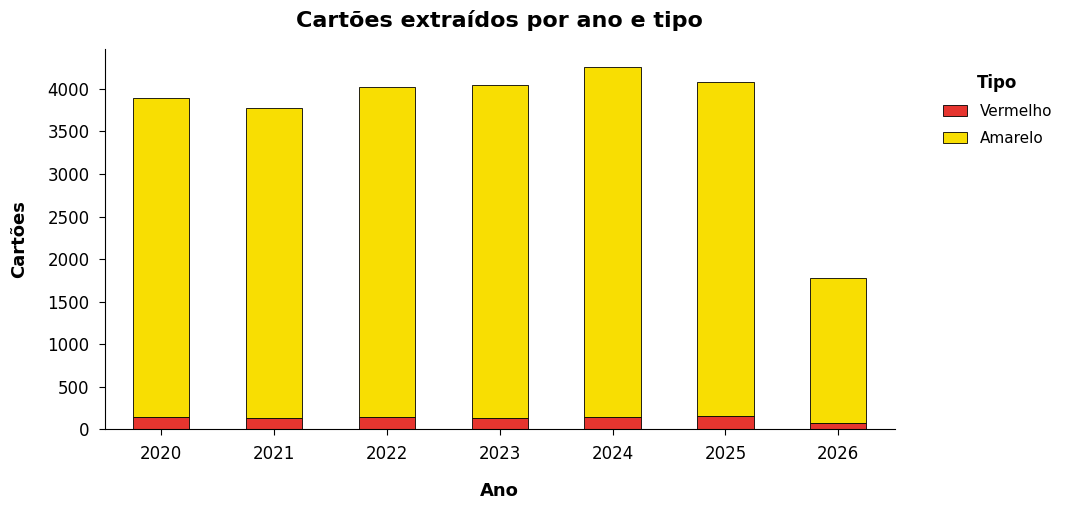

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.4))
card_by_year_type.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[PLOT_CARD_COLORS.get(column, PLOT_BLUE) for column in card_by_year_type.columns],
    edgecolor="black",
    linewidth=0.6,
)
style_axis(ax, "Cartões extraídos por ano e tipo", "Ano", "Cartões")
handles, labels = ax.get_legend_handles_labels()
label_map = {"yellow": "Amarelo", "red": "Vermelho"}
ax.legend(handles, [label_map.get(label, label) for label in labels], title="Tipo", loc="upper left", bbox_to_anchor=(1.03, 1), frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
ax.get_legend().get_title().set_fontweight("bold")
plt.tight_layout(pad=1.5)
save_plot(fig, "cards_by_year_type.png")
plt.show()

In [8]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()
card_text_counts.head(25)

,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,503,503,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",411,411,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,286,285,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,251,250,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",237,237,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,230,230,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por impedir um ataque promissor,Por impedir um ataque promissor.,203,203,0
9,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0


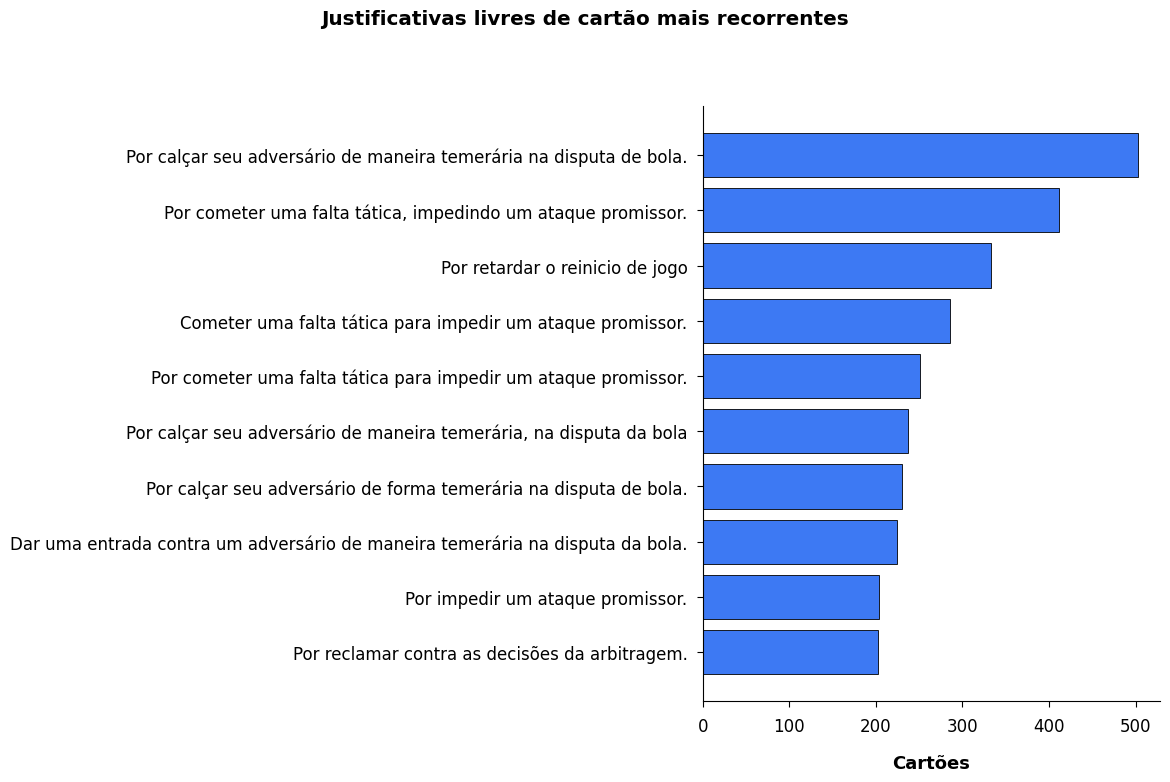

In [9]:
plot_top_texts = card_text_counts.head(TOP_N_CARD_TEXTS).sort_values("n_events")
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(plot_top_texts["text_for_embedding"], plot_top_texts["n_events"], color=PLOT_BLUE, edgecolor="black", linewidth=0.6)
style_axis(ax, None, "Cartões", "")
fig.suptitle("Justificativas livres de cartão mais recorrentes", fontweight="bold", x=0.5, y=0.985)
plt.tight_layout(rect=(0, 0, 1, 0.95), pad=1.5)
save_plot(fig, "top_card_reason_texts.png")
plt.show()

### **4.1 Conclusões da EDA dos Cartões**

A base contém 25.752 cartões, sendo 24.818 amarelos e 934 vermelhos. Essa assimetria indica que o problema não deve ser tratado como uma classificação balanceada de tipos de cartão; o foco metodológico é agrupar justificativas textuais por significado.

Os 6.919 textos únicos mostram alta diversidade lexical, mas os exemplos mais frequentes se concentram em padrões claros: ação temerária, falta tática para impedir ataque promissor, retardar reinício e reclamações contra a arbitragem. Essa combinação de repetição e variação justifica o uso de embeddings: textos próximos semanticamente podem ser agrupados mesmo quando a redação não é idêntica.

O volume de 2026 é menor porque a temporada está incompleta na coleta, portanto as comparações temporais devem considerar esse recorte parcial.

## **5. Funções Auxiliares**

- `make_topic_model` — cria BERTopic com `embedding_model=None` para usar embeddings pré-calculados; UMAP com `n_components=5`, `metric="cosine"` e `min_dist=0.0` conforme recomendação do BERTopic.
- `load_embedding_model` — carrega `SentenceTransformer` com fallback para transformer puro + mean pooling.
- `dbcv_no_outliers` — calcula o DBCV (Density-Based Clustering Validation) nos embeddings UMAP reduzidos (5d), espaço onde o HDBSCAN efetivamente clusteriza; retorna `nan` se há menos de 2 clusters.
- `build_topic_summary` — agrega contagens de eventos e termos top por cluster.
- `top_examples_by_topic` — exemplos representativos por tópico, ordenados por frequência.
- `print_cluster_inspection` — formata clusters para inspeção antes da rotulagem semântica.


In [10]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}

def make_topic_model(min_topic_size: int, n_neighbors: int = 15) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(n_components=5, n_neighbors=n_neighbors, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE)
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        vectorizer_model=vectorizer_model,
        min_topic_size=min_topic_size,
        calculate_probabilities=False,
        verbose=False,
    )

def dbcv_no_outliers(umap_embeddings: np.ndarray, labels) -> float:
    arr = np.array(labels)
    mask = arr != -1
    if mask.sum() < 2 or len(set(arr[mask])) < 2:
        return float('nan')
    try:
        return float(_hdbscan_validity(umap_embeddings[mask].astype(np.float64), arr[mask]))
    except Exception:
        return float('nan')

def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])

def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)

def top_examples_by_topic(text_counts: pd.DataFrame, topic_col: str, top_n: int = 5) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )


def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model

def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()

def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("-" * 110)
    for _, row in summary.iterrows():
        topic_id = int(row[topic_col])
        n_events = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if topic_id == -1 else ""
        print(f"\n{topic_id:>4}  {n_events:>8,}  {terms}{suffix}")
        examples = examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist()
        for example in examples:
            print(f"              > {str(example)[:108]}")

## **6. Pipeline NLP — Motivos de Cartão**

Arquitetura de duas passagens: o modelo base produz clusters exploratórios que geram os pares de treino para o fine-tuning; o modelo fine-tunado produz os clusters finais usados na rotulagem semântica.

### **6.1 Embeddings Base**

`multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas. O modelo exige prefixos `passage:` nos textos a indexar e `query:` nas consultas — protocolo obrigatório da família E5 para maximizar a qualidade dos embeddings.

Trabalhar sobre textos únicos — e não sobre todas as ocorrências — reduz o custo computacional do UMAP+HDBSCAN e elimina o viés de duplicatas nos embeddings de cluster.


In [11]:
base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base: {base_card_embeddings.shape}")

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7471.13it/s]


[OK] SentenceTransformer: intfloat/multilingual-e5-large


Batches: 100%|██████████| 109/109 [00:38<00:00,  2.80it/s]

Embeddings base: (6945, 1024)


### **6.2 Seleção de Hiperparâmetros UMAP e HDBSCAN**

Os dois parâmetros com maior impacto na qualidade dos clusters são `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN), conforme documentado por Grootendorst (2022):

- **`n_neighbors`** — equilíbrio entre estrutura local e global na projeção UMAP. Valores menores criam fronteiras mais nítidas; valores maiores capturam estrutura global.
- **`min_topic_size`** — threshold de densidade do HDBSCAN; determina o número de clusters e a taxa de outliers.

`min_dist=0.0` é fixado conforme recomendação explícita do BERTopic para maximizar a densidade dos clusters. O DBCV (Density-Based Clustering Validation, Moulavi et al. 2014) é a métrica de seleção — calculado sobre os embeddings UMAP reduzidos (5d), espaço onde o HDBSCAN efetivamente clusteriza; maior DBCV indica melhor separação densidade-baseada. Os resultados do grid search são salvos em CSV e reutilizados em execuções subsequentes.


Grid search: n_neighbors x min_topic_size (modelo base)...
  [ 1/45] n_neighbors=10 | min_topic_size=10 | clusters=212 | outliers= 977 | dbcv=0.6549
  [ 2/45] n_neighbors=10 | min_topic_size=15 | clusters=142 | outliers=1246 | dbcv=0.6923
  [ 3/45] n_neighbors=10 | min_topic_size=20 | clusters=105 | outliers=1203 | dbcv=0.6827
  [ 4/45] n_neighbors=10 | min_topic_size=25 | clusters= 86 | outliers=1430 | dbcv=0.6833
  [ 5/45] n_neighbors=10 | min_topic_size=30 | clusters= 56 | outliers= 907 | dbcv=0.6998
  [ 6/45] n_neighbors=10 | min_topic_size=35 | clusters= 47 | outliers= 932 | dbcv=0.6469
  [ 7/45] n_neighbors=10 | min_topic_size=40 | clusters= 38 | outliers= 618 | dbcv=0.5924
  [ 8/45] n_neighbors=10 | min_topic_size=45 | clusters= 31 | outliers= 477 | dbcv=0.6049
  [ 9/45] n_neighbors=10 | min_topic_size=60 | clusters= 24 | outliers= 459 | dbcv=0.6581
  [10/45] n_neighbors=15 | min_topic_size=10 | clusters=185 | outliers=1186 | dbcv=0.6750
  [11/45] n_neighbors=15 | min_topic_size

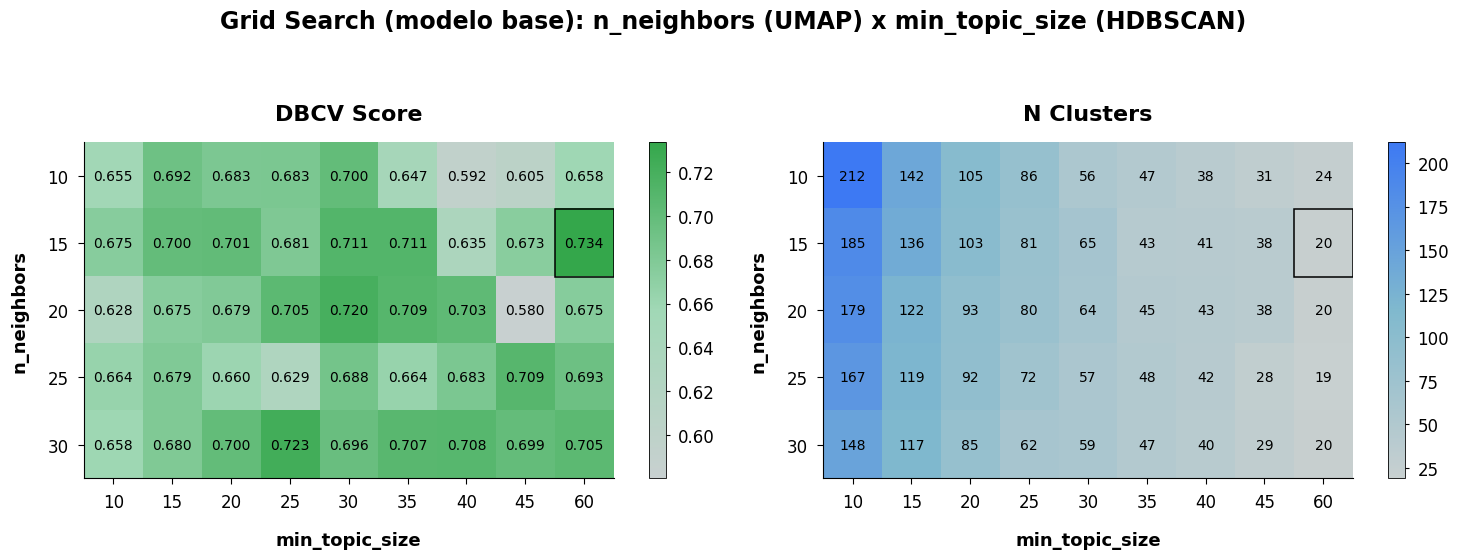

,n_neighbors,min_topic_size,n_clusters,n_outliers,outlier_pct,dbcv
0,10,10,212,977,0.141,0.654911
1,10,15,142,1246,0.179,0.692295
2,10,20,105,1203,0.173,0.682677
3,10,25,86,1430,0.206,0.683298
4,10,30,56,907,0.131,0.699826
5,10,35,47,932,0.134,0.646870
6,10,40,38,618,0.089,0.592357
7,10,45,31,477,0.069,0.604897
8,10,60,24,459,0.066,0.658122
9,15,10,185,1186,0.171,0.674951


In [12]:
MODEL_SLUG = MODEL_NAME.replace("/", "_")
GRID_SEARCH_BASE_PATH = OUTPUT_DIR / f"grid_search_results_base_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH = False

N_NEIGHBORS_RANGE = [10, 15, 20, 25, 30]
MIN_TOPIC_SIZE_RANGE = [10, 15, 20, 25, 30, 35, 40, 45, 60]

def _ranges_match(df: pd.DataFrame) -> bool:
    return (
        sorted(df["n_neighbors"].unique().tolist()) == sorted(N_NEIGHBORS_RANGE)
        and sorted(df["min_topic_size"].unique().tolist()) == sorted(MIN_TOPIC_SIZE_RANGE)
    )

def _run_grid_search(embeddings: np.ndarray, label: str) -> pd.DataFrame:
    combos = [(n, m) for n in N_NEIGHBORS_RANGE for m in MIN_TOPIC_SIZE_RANGE]
    results = []
    for i, (n_nb, mts) in enumerate(combos):
        _m = make_topic_model(mts, n_neighbors=n_nb)
        _topics, _ = _m.fit_transform(card_texts, embeddings=embeddings)
        _n_clusters = len(set(_topics) - {-1})
        _n_outliers = int((np.array(_topics) == -1).sum())
        _umap_embs = _m.umap_model.embedding_
        _dbcv = dbcv_no_outliers(_umap_embs, _topics)
        results.append({"n_neighbors": n_nb, "min_topic_size": mts,
                         "n_clusters": _n_clusters, "n_outliers": _n_outliers,
                         "outlier_pct": round(_n_outliers / len(_topics), 3), "dbcv": _dbcv})
        print(f"  [{i+1:2d}/{len(combos)}] n_neighbors={n_nb:2d} | min_topic_size={mts:2d} | clusters={_n_clusters:3d} | outliers={_n_outliers:4d} | dbcv={float(_dbcv):.4f}")
    return pd.DataFrame(results)

if not RERUN_GRID_SEARCH and GRID_SEARCH_BASE_PATH.exists():
    grid_df = pd.read_csv(GRID_SEARCH_BASE_PATH)
    if not _ranges_match(grid_df) or "dbcv" not in grid_df.columns:
        print("Ranges alterados ou coluna DBCV ausente — re-executando grid search base...")
        RERUN_GRID_SEARCH = True
    else:
        print(f"Grid search base carregado do cache ({GRID_SEARCH_BASE_PATH.name})")

if RERUN_GRID_SEARCH or not GRID_SEARCH_BASE_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo base)...")
    grid_df = _run_grid_search(base_card_embeddings, "base")
    grid_df.to_csv(GRID_SEARCH_BASE_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_BASE_PATH}")

valid_grid = grid_df.dropna(subset=["dbcv"])
best_row = valid_grid.loc[valid_grid["dbcv"].idxmax()]
best_n_neighbors = int(best_row["n_neighbors"])
best_min_topic_size = int(best_row["min_topic_size"])
print()
print(f"Melhores parâmetros (base): n_neighbors={best_n_neighbors}, min_topic_size={best_min_topic_size}")
print(f"DBCV: {best_row['dbcv']:.4f} | clusters: {int(best_row['n_clusters'])} | outliers: {int(best_row['n_outliers'])}")

dbcv_pivot = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="dbcv")
nc_pivot  = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="n_clusters")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, pivot, title, cmap in zip(
    axes, [dbcv_pivot, nc_pivot], ["DBCV Score", "N Clusters"], [PLOT_HEATMAP_GREEN, PLOT_HEATMAP_BLUE],
):
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(MIN_TOPIC_SIZE_RANGE)))
    ax.set_xticklabels(MIN_TOPIC_SIZE_RANGE)
    ax.set_yticks(range(len(N_NEIGHBORS_RANGE)))
    ax.set_yticklabels(N_NEIGHBORS_RANGE)
    style_axis(ax, title, "min_topic_size", "n_neighbors")
    for ii in range(len(N_NEIGHBORS_RANGE)):
        for jj in range(len(MIN_TOPIC_SIZE_RANGE)):
            val = pivot.iloc[ii, jj]
            ax.text(jj, ii, f"{val:.3f}" if title == "DBCV Score" else str(int(val)), ha="center", va="center", fontsize=10, color="black")
    colorbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.06)
    style_colorbar(colorbar)
    best_i = N_NEIGHBORS_RANGE.index(best_n_neighbors)
    best_j = MIN_TOPIC_SIZE_RANGE.index(best_min_topic_size)
    ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=1.1))

fig.suptitle("Grid Search (modelo base): n_neighbors (UMAP) x min_topic_size (HDBSCAN)", fontsize=17, fontweight="bold", y=1.03)
plt.tight_layout(pad=1.6)
save_plot(fig, "umap_param_grid_search_base.png")
plt.show()
grid_df

### **6.3 BERTopic — Passagem 1 (Exploração)**

Clustering com o modelo base. Os tópicos encontrados **não** são os rótulos finais — servem exclusivamente como fonte de pares positivos para o fine-tuning. Textos no mesmo cluster HDBSCAN formam pares semanticamente coerentes; outliers (label -1) são descartados por não pertencerem a nenhum grupo denso.


In [13]:
card_topic_model_pass1 = make_topic_model(best_min_topic_size, n_neighbors=best_n_neighbors)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(card_texts, embeddings=base_card_embeddings)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

n_clusters_pass1 = len(set(card_topics_pass1) - {-1})
n_outliers_pass1 = int((np.array(card_topics_pass1) == -1).sum())
dbcv_pass1 = dbcv_no_outliers(card_topic_model_pass1.umap_model.embedding_, card_topics_pass1)

pass1_counts = card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"})
pass1_summary = build_topic_summary(card_topic_model_pass1, pass1_counts, "bertopic_topic")
pass1_summary = pass1_summary.rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters: {n_clusters_pass1} | outliers: {n_outliers_pass1} ({100*n_outliers_pass1/len(card_topics_pass1):.1f}%) | dbcv: {dbcv_pass1:.4f}")
pass1_summary.head(20)

Pass 1 — clusters: 20 | outliers: 255 (3.7%) | dbcv: 0.7338


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,2,974,2_ataque_promissor_ataque promissor_impedindo,"[ataque, promissor, ataque promissor, impedindo, impedindo ataque, impedindo ataque promissor, adversário impedindo, adversário impedindo ataque, cometer falta, cometer]","[Por obstruir a passagem do seu adversário impedindo um ataque promissor ., Cometer uma falta táctica impedindo um ataque promissor, Por cometer uma falta impudente impedindo um ataque promissor.]",974,4077,"ataque, promissor, ataque promissor, impedindo, impedindo ataque, impedindo ataque promissor, adversário impedindo, adversário impedindo ataque"
1,1,1033,1_arbitragem_decisões_decisões arbitragem_reclamar,"[arbitragem, decisões, decisões arbitragem, reclamar, arbitragem reclamar, desaprovar, gestos, palavras, acintosa, decisão]","[Reclamar contras decisões da arbitragem., Por reclamar demasiadamente das decisões da arbitragem., Reclamar demasiadamente contra as decisões da arbitragem.]",1033,4068,"arbitragem, decisões, decisões arbitragem, reclamar, arbitragem reclamar, desaprovar, gestos, palavras"
2,6,276,6_adversário temerária_calçar_temerária_calçar adversário,"[adversário temerária, calçar, temerária, calçar adversário, temerária calçar, calçar adversário temerária, adversário temerária calçar, adversário, temerária calçar adversário, golpear adversário temerária]","[Ao calçar o adversário de forma temerária., Por calçar o seu adversário de maneira temerária., Por calçar um adversário de maneira temerária na disputa da bola.]",276,3092,"adversário temerária, calçar, temerária, calçar adversário, temerária calçar, calçar adversário temerária, adversário temerária calçar, adversário"
3,0,1153,0_desrespeito_antidesportiva_adversário_mostrar,"[desrespeito, antidesportiva, adversário, mostrar, conduta, mostrar desrespeito, conduta antidesportiva, mostrando, atitude, mostrando desrespeito]","[Conduta antidesportiva - desrespeito ao jogo., Por conduta antidesportiva ao atuar de maneira a mostrar desrespeito ao jogo segurando um adversário de maneira acintosa., Por conduta antidesportiva, empurrar seu adve...",1153,2554,"desrespeito, antidesportiva, adversário, mostrar, conduta, mostrar desrespeito, conduta antidesportiva, mostrando"
4,10,191,10_entrada_dar entrada_entrada temerária_dar,"[entrada, dar entrada, entrada temerária, dar, entrada temerária adversário, dar entrada temerária, adversário dar entrada, temerária, temerária dar entrada, temerária adversário]","[Por dar uma entrada de maneira temerária contra um adversário na disputa de bola., Por dar uma entrada temerária no seu adversário na disputa de bola., Por dar uma entrada de forma temerária, na disputa da bola, con...",191,2469,"entrada, dar entrada, entrada temerária, dar, entrada temerária adversário, dar entrada temerária, adversário dar entrada, temerária"
5,3,685,3_retardar_reinício_longe_retardar reinício,"[retardar, reinício, longe, retardar reinício, chutar, tiro, chutar longe, cobrança, tiro meta, meta]","[Por chutar a bola para longe para retardar o reinício de jogo., Chutar a bola para longe para retardar o reinício de jogo., Por retardar o reinício de jogo ao chutar a bola para longe.]",685,1898,"retardar, reinício, longe, retardar reinício, chutar, tiro, chutar longe, cobrança"
6,12,152,12_entrada_dar entrada_dar_temerária dar entrada,"[entrada, dar entrada, dar, temerária dar entrada, dar entrada adversário, entrada adversário, entrada temerária, dar entrada temerária, temerária dar, adversário dar entrada]","[Dar uma entrada contra seu adversário de maneira temerária na disputa pela bola, Dar entrada em um adversário de maneira temerária na disputa de bola., Dar uma entrada contra seu adversário de maneira temerária em d...",152,1486,"entrada, dar entrada, dar, temerária dar entrada, dar entrada adversário, entrada adversário, entrada temerária, dar entrada temerária"
7,14,100,14_calçar_temerária calçar_adversário temerária 

### **6.4 Fine-Tuning do Sentence Transformer**

`MultipleNegativesRankingLoss` trata cada par `(âncora, positivo)` no batch como positivo; os demais positivos no mesmo batch atuam como negativos implícitos. Esta formulação — usada em dense retrieval (Karpukhin et al., 2020) e contrastive learning de sentenças (Gao et al., 2021 / SimCSE) — é eficiente computacionalmente e adequada para corpus pequeno com vocabulário especializado.

A geração automática de pares a partir dos clusters do BERTopic é uma forma de *self-supervised contrastive learning*: a própria estrutura semântica descoberta na Passagem 1 fornece o sinal de supervisão, sem necessidade de rótulos manuais.


In [14]:
def build_pairs_from_labels(
    text_counts: pd.DataFrame,
    labels,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
    prefix: str = "",
) -> list[dict]:
    df = text_counts.copy()
    df["_label"] = labels
    pairs: list[dict] = []
    for lbl, group in df.groupby("_label"):
        if int(lbl) == -1:
            continue
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna().astype(str).str.strip()
            .loc[lambda s: s.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": prefix + a, "positive": prefix + b}
            for a, b in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs

if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers
        import sentence_transformers.base.trainer as st_base_trainer

        if not hasattr(st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as TorchIterableDataset
            st_base_trainer.IterableDataset = TorchIterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_labels(
            card_text_counts, card_topics_pass1, prefix=ENCODE_PREFIX_PASSAGE
        )
        n_outlier_texts = int((np.array(card_topics_pass1) == -1).sum())
        if not positive_pairs:
            raise ValueError("Nenhum par positivo gerado pelo BERTopic Pass 1.")
        print(f"Pares positivos gerados (BERTopic Pass 1): {len(positive_pairs):,}")
        print(f"Textos outlier excluídos: {n_outlier_texts}")

        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado. Usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")

Pares positivos gerados (BERTopic Pass 1): 9,000
Textos outlier excluídos: 255


/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_93070/2922591343.py:35: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers.losses import MultipleNegativesRankingLoss
/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_93070/2922591343.py:36: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 5871.47it/s]
The `warmup_ratio` argument is deprecated in Transformers v5+, and will also be removed from Sentence Transformers once support for Transformers v4 is dropped. Since you're using Transformers v5+, please use `warmup_steps` (as a 

[OK] SentenceTransformer: intfloat/multilingual-e5-large


Step,Training Loss
50,1.536013
100,0.848368
150,0.805658
200,0.729180
250,0.743060


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.60s/it]


Modelo salvo em: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass
Dimensão dos embeddings: 1024


### **6.5 BERTopic — Passagem 2 (Clusters Finais)**

O modelo fine-tunado gera embeddings com maior separabilidade intra-domínio. Um segundo grid search é executado sobre os embeddings fine-tunados — os hiperparâmetros ótimos podem diferir dos da Passagem 1, pois a geometria do espaço de embeddings muda após o fine-tuning.


In [15]:
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões: {card_embeddings.shape}")

Batches:   0%|          | 0/109 [00:00<?, ?it/s]

Batches: 100%|██████████| 109/109 [02:15<00:00,  1.24s/it]

Embeddings de cartões: (6945, 1024)


In [16]:
GRID_SEARCH_FT_PATH = OUTPUT_DIR / f"grid_search_results_ft_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH_FT = RETRAIN_FINETUNED_MODEL

if not RERUN_GRID_SEARCH_FT and GRID_SEARCH_FT_PATH.exists():
    grid_ft_df = pd.read_csv(GRID_SEARCH_FT_PATH)
    if not _ranges_match(grid_ft_df) or "dbcv" not in grid_ft_df.columns:
        print("Ranges alterados ou coluna DBCV ausente — re-executando grid search FT...")
        RERUN_GRID_SEARCH_FT = True
    else:
        print(f"Grid search FT carregado do cache ({GRID_SEARCH_FT_PATH.name})")

if RERUN_GRID_SEARCH_FT or not GRID_SEARCH_FT_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo fine-tunado)...")
    grid_ft_df = _run_grid_search(card_embeddings, "ft")
    grid_ft_df.to_csv(GRID_SEARCH_FT_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_FT_PATH}")

valid_ft = grid_ft_df.dropna(subset=["dbcv"])
best_row_ft = valid_ft.loc[valid_ft["dbcv"].idxmax()]
best_n_neighbors_ft = int(best_row_ft["n_neighbors"])
best_min_topic_size_ft = int(best_row_ft["min_topic_size"])
print(f"\nMelhores parâmetros (fine-tunado): n_neighbors={best_n_neighbors_ft}, min_topic_size={best_min_topic_size_ft}")
print(f"DBCV: {best_row_ft['dbcv']:.4f} | clusters: {int(best_row_ft['n_clusters'])} | outliers: {int(best_row_ft['n_outliers'])}")

Grid search: n_neighbors x min_topic_size (modelo fine-tunado)...
  [ 1/45] n_neighbors=10 | min_topic_size=10 | clusters=220 | outliers=1021 | dbcv=0.7215
  [ 2/45] n_neighbors=10 | min_topic_size=15 | clusters=153 | outliers=1150 | dbcv=0.7159
  [ 3/45] n_neighbors=10 | min_topic_size=20 | clusters=117 | outliers=1243 | dbcv=0.7182
  [ 4/45] n_neighbors=10 | min_topic_size=25 | clusters= 73 | outliers= 665 | dbcv=0.7042
  [ 5/45] n_neighbors=10 | min_topic_size=30 | clusters= 50 | outliers= 473 | dbcv=0.6935
  [ 6/45] n_neighbors=10 | min_topic_size=35 | clusters= 43 | outliers= 420 | dbcv=0.7871
  [ 7/45] n_neighbors=10 | min_topic_size=40 | clusters= 35 | outliers= 389 | dbcv=0.7983
  [ 8/45] n_neighbors=10 | min_topic_size=45 | clusters= 30 | outliers= 306 | dbcv=0.7796
  [ 9/45] n_neighbors=10 | min_topic_size=60 | clusters= 25 | outliers= 162 | dbcv=0.7418
  [10/45] n_neighbors=15 | min_topic_size=10 | clusters=201 | outliers=1131 | dbcv=0.7200
  [11/45] n_neighbors=15 | min_top

In [17]:
card_topic_model = make_topic_model(best_min_topic_size_ft, n_neighbors=best_n_neighbors_ft)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

n_clusters_pass2 = len(set(card_topics) - {-1})
n_outliers_pass2 = int((np.array(card_topics) == -1).sum())
dbcv_pass2 = dbcv_no_outliers(card_topic_model.umap_model.embedding_, card_topics)

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters: {n_clusters_pass2} | outliers: {n_outliers_pass2} ({100*n_outliers_pass2/len(card_topics):.1f}%) | dbcv: {dbcv_pass2:.4f}")
card_topic_summary.head(20)

Pass 2 — clusters: 39 | outliers: 340 (4.9%) | dbcv: 0.8541


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,1,1043,1_arbitragem_decisões_decisões arbitragem_reclamar,"[arbitragem, decisões, decisões arbitragem, reclamar, desaprovar, gestos, palavras, decisão, decisão arbitragem, acintosa]","[Por reclamar com palavras das decisões da arbitragem., Reclamar contras decisões da arbitragem., Reclamar demasiadamente contra as decisões da arbitragem.]",1043,4066,"arbitragem, decisões, decisões arbitragem, reclamar, desaprovar, gestos, palavras, decisão"
1,0,1074,0_desrespeito_antidesportiva_mostrar_mostrar desrespeito,"[desrespeito, antidesportiva, mostrar, mostrar desrespeito, conduta, adversário, mostrando, conduta antidesportiva, mostrando desrespeito, empurrar]","[Por atuar de maneira a mostrar desrespeito ao jogo ao segurar seu adversário de maneira acintosa., Conduta antidesportiva ao atuar de maneira a mostrar desrespeito ao jogo., Por conduta antidesportiva, mostrando des...",1074,2427,"desrespeito, antidesportiva, mostrar, mostrar desrespeito, conduta, adversário, mostrando, conduta antidesportiva"
2,7,172,7_calçar_calçar adversário_calçar adversário temerária_temerária calçar,"[calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário temerária, temerária, adversário calçar, adversário]","[Por calçar seu adversário de forma temerária na disputa de jogo., Por calçar seu adversário de maneira temerária na dispuitra de bola., Por calçar o atleta adversário de forma temerária.]",172,2291,"calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário temerária, temerária"
3,6,180,6_dar entrada_entrada_dar_temerária dar entrada,"[dar entrada, entrada, dar, temerária dar entrada, dar entrada adversário, entrada adversário, entrada temerária, dar entrada temerária, adversário dar entrada, entrada adversário temerária]","[dar uma entrada contra seu adversário de maneira temerária na disputa de bola., Dar uma entrada em um adversário de maneira temerária em disputa de bola., Dar uma entrada no adversário de maneira temerária]",180,1602,"dar entrada, entrada, dar, temerária dar entrada, dar entrada adversário, entrada adversário, entrada temerária, dar entrada temerária"
4,23,84,23_entrada adversário temerária_temerária dar entrada_entrada adversário_dar entrada adversário,"[entrada adversário temerária, temerária dar entrada, entrada adversário, dar entrada adversário, entrada, dar entrada, temerária dar, adversário temerária dar, dar, adversário temerária]","[Por dar um entrada contra seu adversário de maneira temerária na disputa da bola., Por dar uma entrada em um adversário de forma temerária na disputa da bola., Por dar uma entrada no adversário, de maneira temerária...",84,1477,"entrada adversário temerária, temerária dar entrada, entrada adversário, dar entrada adversário, entrada, dar entrada, temerária dar, adversário temerária dar"
5,3,392,3_retardar_reinício_tiro_retardar reinício,"[retardar, reinício, tiro, retardar reinício, tiro meta, cobrança, meta, meta retardar, tiro meta retardar, execução]","[Por retardar o reinicio de jogo em uma cobrança de tiro de meta., Por retardar o reinicio do jogo na cobrança do tiro de meta, Por retardar o reinício da partida na reposição de tiro de meta.]",392,1201,"retardar, reinício, tiro, retardar reinício, tiro meta, cobrança, meta, meta retardar"
6,-1,340,-1_ataque_ataque promissor_promissor_cometer falta,"[ataque, ataque promissor, promissor, cometer falta, gol, cometer, falta, impedindo ataque, impedindo ataque promissor, tática]","[Cometer falta tática para impedir um ataque promissor., Cometer uma falta tática impedindo ataque promissor., Cometer uma falta tática impedindo o ataque promissor.]",340,1082,outliers
7,15,108,15_calçar_temerária calçar_adversário temerária calçar_calçar adversário,"[calçar, temerária calçar, advers

In [18]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)

,bertopic_topic,n_events,text_for_embedding
0,-1,286,Cometer uma falta tática para impedir um ataque promissor.
1,-1,55,Cometer uma falta tática impedindo ataque promissor.
2,-1,35,Por impedir um ataque promissor da equipe adversária.
3,-1,24,Por dar uma entrada temerária contra seu adversário.
4,-1,19,Por dar uma entrada temerária em seu adversário.
5,0,68,Atuar de maneira a mostrar desrespeito ao jogo.
6,0,63,Por atuar de maneira a mostrar desrespeito ao jogo.
7,0,49,Por conduta antidesportiva.
8,0,37,Por atitude antidesportiva
9,0,30,Por segurar seu adversario de forma acintosa mostrando desrespeito ao jogo.


### **6.6 Ablação: Modelo Base vs. Fine-Tunado**

Comparação direta entre Pass 1 (modelo base) e Pass 2 (modelo fine-tunado) usando os hiperparâmetros ótimos de cada passagem. As métricas — número de clusters, taxa de outliers e DBCV Score — quantificam o ganho do fine-tuning na separabilidade semântica dos embeddings no espaço UMAP reduzido (5d).

O modelo baseline (`paraphrase-multilingual-mpnet-base-v2`, 768 dim) foi avaliado na mesma configuração e serviu de referência para a adoção do `multilingual-e5-large`.


Ganho de DBCV: +16.4%


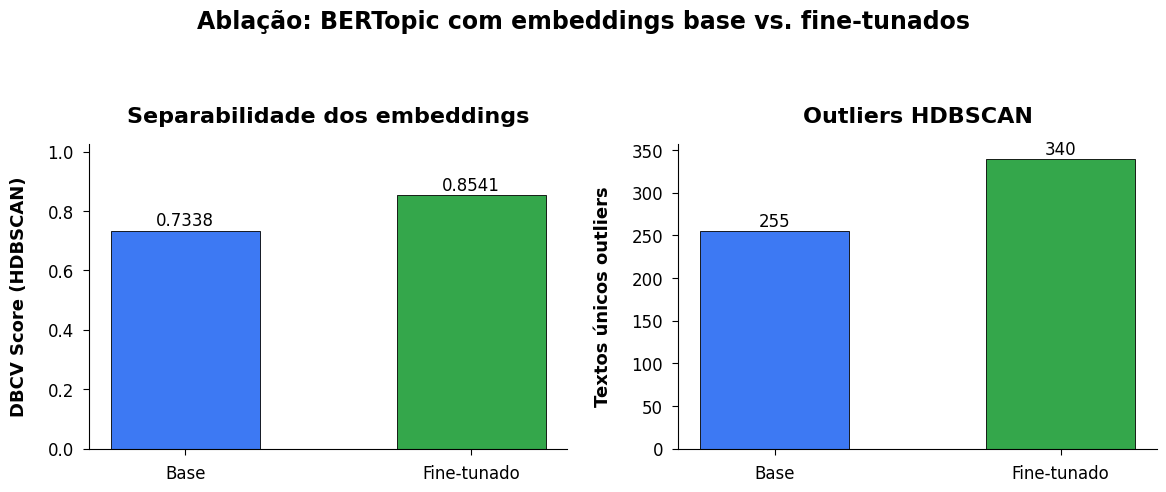

,Passagem,n_neighbors,min_topic_size,N Clusters,Outliers,Outlier %,DBCV Score
0,Pass 1 — Modelo base,15,60,20,255,3.7%,0.7338
1,Pass 2 — Fine-tunado,25,35,39,340,4.9%,0.8541


In [19]:
outlier_pct_pass1 = 100 * n_outliers_pass1 / len(card_topics_pass1)
outlier_pct_pass2 = 100 * n_outliers_pass2 / len(card_topics)
dbcv_gain = (dbcv_pass2 - dbcv_pass1) / abs(dbcv_pass1) * 100 if dbcv_pass1 != 0 else float("nan")

ablation_table = pd.DataFrame({
    "Passagem": ["Pass 1 — Modelo base", "Pass 2 — Fine-tunado"],
    "n_neighbors": [best_n_neighbors, best_n_neighbors_ft],
    "min_topic_size": [best_min_topic_size, best_min_topic_size_ft],
    "N Clusters": [n_clusters_pass1, n_clusters_pass2],
    "Outliers": [n_outliers_pass1, n_outliers_pass2],
    "Outlier %": [f"{outlier_pct_pass1:.1f}%", f"{outlier_pct_pass2:.1f}%"],
    "DBCV Score": [round(dbcv_pass1, 4), round(dbcv_pass2, 4)],
})
print(f"Ganho de DBCV: +{dbcv_gain:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
labels = ["Base", "Fine-tunado"]
colors = [PLOT_BLUE, "#34A74B"]

axes[0].bar(labels, [dbcv_pass1, dbcv_pass2], color=colors, width=0.52, edgecolor="black", linewidth=0.6)
for ax_bar, val in zip(axes[0].patches, [dbcv_pass1, dbcv_pass2]):
    axes[0].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.003, f"{val:.4f}", ha="center", va="bottom", fontsize=12)
style_axis(axes[0], "Separabilidade dos embeddings", "", "DBCV Score (HDBSCAN)")
axes[0].set_ylim(min(0, min(dbcv_pass1, dbcv_pass2)) * 1.2, max(dbcv_pass1, dbcv_pass2) * 1.2)

axes[1].bar(labels, [n_outliers_pass1, n_outliers_pass2], color=colors, width=0.52, edgecolor="black", linewidth=0.6)
for ax_bar, val in zip(axes[1].patches, [n_outliers_pass1, n_outliers_pass2]):
    axes[1].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.5, str(val), ha="center", va="bottom", fontsize=12)
style_axis(axes[1], "Outliers HDBSCAN", "", "Textos únicos outliers")

fig.suptitle("Ablação: BERTopic com embeddings base vs. fine-tunados", fontsize=17, fontweight="bold", y=1.04)
plt.tight_layout(pad=1.6)
save_plot(fig, "ablation_dbcv.png")
plt.show()
ablation_table

### **6.7 Conclusão da Avaliação e Seleção do Modelo**

A seleção de hiperparâmetros é feita por grid search em `n_neighbors` e `min_topic_size`, que controlam a geometria da projeção UMAP e a densidade mínima aceita pelo HDBSCAN. A comparação entre a Passagem 1 e a Passagem 2 mostra que o fine-tuning reduz a taxa de outliers e melhora a separação dos clusters no espaço reduzido.

O modelo final escolhido é a segunda passagem com embeddings fine-tunados, pois ela mantém número de clusters interpretável e reduz o ruído HDBSCAN. Essa decisão controla overfitting ao usar apenas uma epoch de fine-tuning e ao validar o resultado por métricas de clusterização e inspeção qualitativa dos tópicos.

## **7. Rotulagem Semântica Manual dos Clusters**

O BERTopic agrupa os textos, mas a decisão semântica final fica em arquivos manuais. A regra operacional é:

- clusters `0` a `101`: um grupo manual por cluster em `card_reason_manual_cluster_labels.csv`;
- outliers `-1`: um grupo manual por texto em `card_reason_manual_outlier_labels.csv`;
- âncoras lexicais de alta precisão são aplicadas antes do grupo do cluster para corrigir clusters mistos, especialmente `temerária/temerário`, `jogo brusco grave`, `força excessiva`, DOGSO, simulação, mão na bola e distância regulamentar.

A taxonomia segue a Regra 12 do IFAB e o Livro de Regras CBF 2025/2026, mas usa nomes adaptados ao vocabulário das súmulas. Como HDBSCAN marca ruído com `-1`, os outliers são tratados como itens auditáveis, não enviados a modelo generativo.

### Score de Representatividade

Para cada grupo, o notebook calcula um centroide ponderado por `n_events`. O score de cada texto é a similaridade cosseno entre o embedding do texto e o centroide do seu grupo. Também é calculada a margem contra o grupo alternativo mais próximo.

- `representativeness_score` alto: texto central no grupo proposto;
- `representativeness_margin` baixo: texto perto de outro grupo, bom candidato para revisão;
- `low_representativeness`: flag inicial para revisão manual.

### Referências

- [IFAB — Law 12: Fouls and Misconduct](https://www.theifab.com/laws/latest/fouls-and-misconduct/?hl=en-US)
- [CBF — Livro de Regras 2025/2026 Português/Brasileiro](https://www.cbf.com.br/a-cbf/por-dentro-da-cbf/informes/a/livro-de-regras-2025-2026)
- [BERTopic — embeddings + c-TF-IDF para tópicos interpretáveis](https://maartengr.github.io/BERTopic/api/bertopic.html)
- [BERTopic — outliers HDBSCAN rotulados como `-1`](https://maartengr.github.io/BERTopic/getting_started/outlier_reduction/outlier_reduction.html)
- [HDBSCAN — ruído e membership score](https://hdbscan.readthedocs.io/en/latest/basic_hdbscan.html)
- [multilingual-e5-large — prefixos `query:` e `passage:`](https://huggingface.co/intfloat/multilingual-e5-large)
- [Sentence Transformers — MultipleNegativesRankingLoss](https://www.sbert.net/docs/package_reference/sentence_transformer/losses.html?highlight=multiplenegativesrankingloss)
- [scikit-learn — cosine_similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)
- [HDBSCAN — validity_index / DBCV](https://hdbscan.readthedocs.io/en/latest/api.html#hdbscan.validity.validity_index)


In [20]:
print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")

  ID   Eventos  Top terms
--------------------------------------------------------------------------------------------------------------

   1     4,066  arbitragem, decisões, decisões arbitragem, reclamar, desaprovar, gestos, palavras, decisão
              > Por reclamar contra as decisões da arbitragem.
              > Por reclamar das decisões da arbitragem.
              > Por desaprovar com palavras e gestos as decisões da arbitragem.

   0     2,427  desrespeito, antidesportiva, mostrar, mostrar desrespeito, conduta, adversário, mostrando, conduta antidesportiva
              > Atuar de maneira a mostrar desrespeito ao jogo.
              > Por atuar de maneira a mostrar desrespeito ao jogo.
              > Por conduta antidesportiva.

   7     2,291  calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário temerária, temerária
              > Por calçar seu adversário de maneira temerária na d

In [21]:
GROUP_TAXONOMY = {
    "Ação temerária":                      "Infrações de contato descritas como temerárias: calçar, entrada, carrinho, tranco, pontapé, rasteira, chute, golpe ou uso de braço em disputa de bola.",
    "Jogo brusco grave":                   "Condutas físicas graves com jogo brusco grave, força excessiva, travas ou risco à integridade física na disputa de bola.",
    "Conduta violenta":                    "Violência ou agressão explícita fora da disputa normal de bola: soco, tapa, cabeçada, cusparada, peitada, golpe ou contato no pescoço.",
    "Falta tática em ataque promissor":    "Falta, segurar, puxar, calçar ou bloquear adversário para impedir ou interromper ataque promissor.",
    "Impedir clara oportunidade de gol":   "Infrações que impedem clara e manifesta oportunidade de gol por falta, carga, segurar ou mão quando descrito no texto.",
    "Retardar reinício do jogo":           "Atraso deliberado de reinício: chutar ou carregar a bola, demorar cobrança, impedir cobrança ou retardar saída em substituição.",
    "Protesto contra a arbitragem":        "Reclamação, protesto, desaprovação ou contestação de decisões da arbitragem por palavras ou gestos.",
    "Insubordinação da comissão técnica":  "Conduta irregular do banco, suplentes ou comissão técnica: sair da área técnica, protestar do banco ou descumprir instruções da arbitragem.",
    "Agarrar ou segurar adversário":       "Agarrar, segurar ou puxar adversário sem sinal explícito de ataque promissor, oportunidade clara de gol ou confronto físico mais amplo.",
    "Confronto físico com adversário":     "Empurrões, troca de empurrões, discussão, tumulto ou confronto físico/verbal com adversário ou outro participante.",
    "Conduta antidesportiva":              "Descrições genéricas de atitude/conduta antidesportiva ou falta de respeito ao jogo quando a ação específica não domina o texto.",
    "Comemoração irregular":               "Comemoração punível: tirar camisa, invadir campo para comemorar, subir em alambrado/arquibancada ou provocar torcida/banco adversário.",
    "Simulação":                           "Simular falta, pênalti ou lesão para enganar a arbitragem.",
    "Toque de mão na bola":                "Toque ou bloqueio da bola com mão/braço, inclusive para interferir em ataque promissor, sem oportunidade clara de gol explícita.",
    "Entrar ou sair do campo sem autorização": "Entrar, reentrar, sair ou retornar ao campo sem autorização; inclui marcas não autorizadas.",
    "Infringir persistentemente as regras": "Persistência em infrações das regras ou número de infrações diferentes, sem se confundir com reclamação persistente.",
    "Não respeitar distância regulamentar": "Não respeitar distância em tiro livre, escanteio, barreira, bola ao chão ou reinício similar.",
    "Gesto ou linguagem ofensiva":         "Xingamentos, insultos, palavras ofensivas/injuriosas, gesto obsceno ou ofensa pessoal explícita.",
}

CLUSTER_TO_GROUP = {
     0: "Jogo brusco grave",
     1: "Jogo brusco grave",
     2: "Confronto físico com adversário",
     3: "Confronto físico com adversário",
     4: "Conduta antidesportiva",
     5: "Protesto contra a arbitragem",
     6: "Toque de mão na bola",
     7: "Ação temerária",
     8: "Infringir persistentemente as regras",
     9: "Ação temerária",
    10: "Confronto físico com adversário",
    11: "Ação temerária",
    12: "Ação temerária",
    13: "Ação temerária",
    14: "Falta tática em ataque promissor",
    15: "Conduta antidesportiva",
    16: "Comemoração irregular",
    17: "Conduta antidesportiva",
    18: "Agarrar ou segurar adversário",
    19: "Retardar reinício do jogo",
    20: "Gesto ou linguagem ofensiva",
    21: "Agarrar ou segurar adversário",
    22: "Protesto contra a arbitragem",
    23: "Ação temerária",
    24: "Ação temerária",
    25: "Agarrar ou segurar adversário",
    26: "Protesto contra a arbitragem",
    27: "Protesto contra a arbitragem",
    28: "Falta tática em ataque promissor",
    29: "Retardar reinício do jogo",
    30: "Insubordinação da comissão técnica",
    31: "Ação temerária",
    32: "Falta tática em ataque promissor",
    33: "Retardar reinício do jogo",
    34: "Simulação",
    35: "Protesto contra a arbitragem",
    36: "Ação temerária",
    37: "Falta tática em ataque promissor",
    38: "Protesto contra a arbitragem",
    39: "Ação temerária",
    40: "Ação temerária",
    41: "Conduta antidesportiva",
    42: "Conduta antidesportiva",
    43: "Retardar reinício do jogo",
    44: "Falta tática em ataque promissor",
    45: "Protesto contra a arbitragem",
    46: "Ação temerária",
    47: "Retardar reinício do jogo",
    48: "Impedir clara oportunidade de gol",
    49: "Falta tática em ataque promissor",
    50: "Falta tática em ataque promissor",
    51: "Insubordinação da comissão técnica",
    52: "Agarrar ou segurar adversário",
    53: "Agarrar ou segurar adversário",
    54: "Protesto contra a arbitragem",
    55: "Insubordinação da comissão técnica",
    56: "Entrar ou sair do campo sem autorização",
    57: "Gesto ou linguagem ofensiva",
    58: "Protesto contra a arbitragem",
    59: "Ação temerária",
    60: "Confronto físico com adversário",
    61: "Ação temerária",
    62: "Falta tática em ataque promissor",
    63: "Falta tática em ataque promissor",
    64: "Comemoração irregular",
    65: "Gesto ou linguagem ofensiva",
    66: "Agarrar ou segurar adversário",
    67: "Ação temerária",
    68: "Ação temerária",
    69: "Falta tática em ataque promissor",
    70: "Confronto físico com adversário",
    71: "Retardar reinício do jogo",
    72: "Retardar reinício do jogo",
    73: "Ação temerária",
    74: "Retardar reinício do jogo",
    75: "Conduta antidesportiva",
    76: "Ação temerária",
    77: "Ação temerária",
    78: "Ação temerária",
    79: "Retardar reinício do jogo",
    80: "Agarrar ou segurar adversário",
    81: "Ação temerária",
    82: "Ação temerária",
    83: "Agarrar ou segurar adversário",
    84: "Comemoração irregular",
    85: "Ação temerária",
    86: "Protesto contra a arbitragem",
    87: "Ação temerária",
    88: "Ação temerária",
    89: "Retardar reinício do jogo",
    90: "Comemoração irregular",
    91: "Ação temerária",
    92: "Protesto contra a arbitragem",
    93: "Ação temerária",
    94: "Comemoração irregular",
    95: "Insubordinação da comissão técnica",
    96: "Ação temerária",
    97: "Confronto físico com adversário",
    98: "Conduta antidesportiva",
    99: "Retardar reinício do jogo",
   100: "Ação temerária",
   101: "Ação temerária",
}

group_contexts = pd.Series(GROUP_TAXONOMY, name="context")
group_contexts.index.name = "group"

valid_groups = set(GROUP_TAXONOMY)
cluster_topics = set(int(t) for t in card_text_counts["bertopic_topic"].unique() if int(t) != -1)

missing_clusters = cluster_topics - set(CLUSTER_TO_GROUP)
invalid_cluster_groups = {g for g in CLUSTER_TO_GROUP.values() if g not in valid_groups}
if missing_clusters:
    print(f"Clusters sem mapeamento: {sorted(missing_clusters)}")
if invalid_cluster_groups:
    print(f"Grupos inválidos no CLUSTER_TO_GROUP: {sorted(invalid_cluster_groups)}")
print(f"{len(GROUP_TAXONOMY)} grupos | {len(CLUSTER_TO_GROUP)} clusters mapeados")

18 grupos | 102 clusters mapeados


In [22]:
CONDUTA_VIOLENTA_EXCLUSIONS = [
    r"socos? no ar",
    r"socos? no chao",
    r"tapa na bola",
    r"simul.*agress",
    r"temerari.{0,80}(na|em) disputa",
    r"(na|em) disputa.{0,80}temerari",
]

MANUAL_PATTERNS = {
    "Conduta violenta": [
        r"conduta violenta",
        r"\bpeitada\b",
        r"\bcabecad",
        r"\bcusp(?:iu|ir|indo|ida|arada)",
        r"\bbrutalidade\b",
        r"\bagred(?:ir|iu|indo|ido|e).*(adversario|arbitro|assistente|atleta|jogador|membro)",
        r"\bagressao\b.*(adversario|arbitro|assistente|atleta|jogador|membro)",
        r"apertar .*pescoco|segur.*pescoco|pescoco.*duas maos",
        r"desfer(?:ir|iu|indo)? .*(soco|tapa|cotovel|golpe|pontape)",
        r"\bsoco\b.*(adversario|rosto|orelha|pescoco|arbitro|assistente|preparador|atleta|jogador)",
        r"\btapa\b.*(rosto|adversario|antebraco|peito|nuca|costas|braco|orelha)",
        r"fora da disputa.*(soco|tapa|cotovel|golp|desfer|ating|chut|pontape|braco|mao|pis)",
        r"(soco|tapa|cotovel|golp|pontape|chute).*(fora da disputa|jogo paralisado|bola fora|fora de jogo)",
        r"(jogo paralisado|bola fora|fora de jogo).*(soco|tapa|cotovel|golp|desfer|ating|cabecad|pescoco|pis)",
    ],
    "Jogo brusco grave": [r"\bjogo brusco grave\b", r"forca excessiva", r"\btravas\b.*(integridade|canela|tornozelo|barriga)"],
    "Impedir clara oportunidade de gol": [r"oportunidade clara", r"clara .*oportunidade", r"manifesta oportunidade", r"\bdogso\b"],
    "Ação temerária": [r"temerari", r"temeridad", r"falta temeraria"],
    "Simulação": [r"\bsimul", r"enganar .*arbitro"],
    "Comemoração irregular": [r"comemor", r"tirar .*camisa", r"retirar .*camisa", r"subir .*arquibancada", r"subir .*alambrado", r"provocativ.*torcida"],
    "Não respeitar distância regulamentar": [r"distancia regulamentar", r"distancia da barreira", r"distancia correta", r"distancia regulamentada"],
    "Retardar reinício do jogo": [r"retardar", r"demorar excessivamente", r"impedir .*cobranca", r"retardar .*saida", r"segur.*bola.*reinicio", r"bola.*maos.*reinicio"],
    "Toque de mão na bola": [r"mao na bola", r"tocar .*bola .*mao", r"colocar .*mao .*bola", r"bloquear .*bola .*braco", r"bola .*mao"],
    "Entrar ou sair do campo sem autorização": [r"entrar .*campo.*sem", r"retornar .*campo.*sem", r"reentrar", r"sem autorizacao", r"sem permissao", r"marcas nao autorizadas"],
    "Gesto ou linguagem ofensiva": [r"filho da puta", r"vai tomar", r"tomar no cu", r"caralho", r"porra", r"merda", r"safado", r"ladrao", r"incompetente", r"maluca", r"gesto obsceno", r"dedo medio", r"orgao genital", r"palavras ofensivas", r"injurios"],
    "Falta tática em ataque promissor": [r"ataque promissor", r"impedir .*ataque", r"impedindo .*ataque", r"cortando .*ataque", r"motivo tatico", r"posicao vantajosa", r"falta tatica"],
    "Insubordinação da comissão técnica": [r"banco de reservas", r"banco de suplentes", r"area tecnica", r"suplente", r"substituto", r"tecnico", r"treinador", r"auxiliar", r"preparador", r"medico", r"massagista", r"comissao tecnica"],
    "Protesto contra a arbitragem": [r"reclam", r"protest", r"desapro", r"contesta", r"question", r"discord", r"aplaud.*iron", r"decisao .*arbitr", r"decisoes .*arbitr", r"marcacao .*arbitr", r"marcacoes .*arbitr"],
    "Agarrar ou segurar adversário": [r"agarr", r"segur", r"pux", r"camisa", r"camiseta"],
    "Confronto físico com adversário": [r"empurr", r"trocar empurroes", r"confront", r"discut", r"desentend", r"tumulto", r"peitada"],
    "Infringir persistentemente as regras": [r"infringir persistentemente", r"numero de diferentes infracoes"],
    "Conduta antidesportiva": [r"conduta antidesportiva", r"atitude antidesportiva", r"desrespeito ao jogo", r"falta de respeito"],
}


def lexical_group(text: str) -> str | None:
    normalized = normalize_text(text)
    for group, patterns in MANUAL_PATTERNS.items():
        if group == "Conduta violenta" and any(re.search(pattern, normalized) for pattern in CONDUTA_VIOLENTA_EXCLUSIONS):
            continue
        if any(re.search(pattern, normalized) for pattern in patterns):
            return group
    return None

In [23]:
def assign_card_reason_group(row: pd.Series) -> str:
    topic = int(row["bertopic_topic"])
    lexical = lexical_group(row["text_for_embedding"])
    if lexical == "Conduta violenta":
        return lexical
    if topic == -1:
        return lexical or "Conduta antidesportiva"
    return lexical if lexical is not None else CLUSTER_TO_GROUP[topic]

card_text_counts["manual_cluster_group"] = card_text_counts["bertopic_topic"].map(CLUSTER_TO_GROUP)
card_text_counts.loc[card_text_counts["bertopic_topic"].eq(-1), "manual_cluster_group"] = "OUTLIER"
card_text_counts["manual_lexical_group"] = card_text_counts["text_for_embedding"].map(lexical_group)
card_text_counts.loc[
    card_text_counts["bertopic_topic"].eq(-1) & card_text_counts["manual_lexical_group"].ne("Conduta violenta"),
    "manual_lexical_group",
] = np.nan
card_text_counts["card_reason_group"] = card_text_counts.apply(assign_card_reason_group, axis=1)
card_text_counts["card_reason_group_context"] = card_text_counts["card_reason_group"].map(group_contexts)

group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
group_context_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group_context"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Conduta antidesportiva")
cards["card_reason_group_context"] = cards[CARD_TEXT_KEY_COLUMN].map(group_context_map).fillna(group_contexts.loc["Conduta antidesportiva"])
CARD_GROUPS = sorted(cards["card_reason_group"].unique())
CARD_GROUP_COLOR_MAP = {group: PLOT_PALETTE[i % len(PLOT_PALETTE)] for i, group in enumerate(CARD_GROUPS)}

pd.Series({
    "groups": len(CARD_GROUPS),
    "clusters_mapped": len(CLUSTER_TO_GROUP),
    "lexical_overrides": int(card_text_counts["manual_lexical_group"].notna().sum()),
    "unlabeled_cards": int(cards["card_reason_group"].isna().sum()),
})

groups                 18
clusters_mapped       102
lexical_overrides    6112
unlabeled_cards         0
dtype: int64

In [24]:
group_order = sorted(card_text_counts["card_reason_group"].unique())
group_to_idx = {group: i for i, group in enumerate(group_order)}
centroids = []

for group in group_order:
    mask = card_text_counts["card_reason_group"].eq(group).to_numpy()
    weights = card_text_counts.loc[mask, "n_events"].to_numpy(dtype=float)
    centroid = np.average(card_embeddings[mask], axis=0, weights=weights)
    centroid = centroid / np.linalg.norm(centroid)
    centroids.append(centroid)

centroid_matrix = np.vstack(centroids)
similarity_to_groups = card_embeddings @ centroid_matrix.T
own_idx = card_text_counts["card_reason_group"].map(group_to_idx).to_numpy()
row_idx = np.arange(len(card_text_counts))
other_similarity = similarity_to_groups.copy()
other_similarity[row_idx, own_idx] = -np.inf
nearest_other_idx = other_similarity.argmax(axis=1)

card_text_counts["representativeness_score"] = similarity_to_groups[row_idx, own_idx]
card_text_counts["nearest_other_group"] = [group_order[i] for i in nearest_other_idx]
card_text_counts["nearest_other_score"] = other_similarity[row_idx, nearest_other_idx]
card_text_counts["representativeness_margin"] = card_text_counts["representativeness_score"] - card_text_counts["nearest_other_score"]
card_text_counts["low_representativeness"] = (
    card_text_counts["representativeness_score"].lt(REPRESENTATIVENESS_MIN_SCORE)
    | card_text_counts["representativeness_margin"].lt(REPRESENTATIVENESS_MIN_MARGIN)
)

card_group_quality = (
    card_text_counts.groupby("card_reason_group")
    .agg(
        n_unique_texts=("text_for_embedding", "size"),
        n_events=("n_events", "sum"),
        score_mean=("representativeness_score", "mean"),
        score_p10=("representativeness_score", lambda s: s.quantile(0.10)),
        margin_mean=("representativeness_margin", "mean"),
        low_score_texts=("low_representativeness", "sum"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)

cluster_quality = (
    card_text_counts[card_text_counts["bertopic_topic"].ne(-1)]
    .groupby("bertopic_topic")
    .agg(
        n_unique_texts=("text_for_embedding", "size"),
        n_events=("n_events", "sum"),
        score_mean=("representativeness_score", "mean"),
        score_p10=("representativeness_score", lambda s: s.quantile(0.10)),
        margin_mean=("representativeness_margin", "mean"),
        low_score_texts=("low_representativeness", "sum"),
    )
    .reset_index()
)

cluster_dominant_group = (
    card_text_counts[card_text_counts["bertopic_topic"].ne(-1)]
    .groupby(["bertopic_topic", "card_reason_group"], as_index=False)["n_events"].sum()
    .sort_values(["bertopic_topic", "n_events"], ascending=[True, False])
    .drop_duplicates("bertopic_topic")
    .rename(columns={"card_reason_group": "dominant_group", "n_events": "dominant_group_events"})
)

card_reason_label_audit_clusters = (
    cluster_quality
    .merge(cluster_dominant_group, on="bertopic_topic", how="left")
    .merge(card_topic_summary[["bertopic_topic", "top_terms"]], on="bertopic_topic", how="left")
    .sort_values(["low_score_texts", "score_p10"], ascending=[False, True])
)

card_reason_label_audit_terms = card_text_counts.sort_values(
    ["low_representativeness", "representativeness_margin", "representativeness_score"],
    ascending=[False, True, True],
)[[
    CARD_TEXT_KEY_COLUMN, "text_for_embedding", "n_events", "bertopic_topic", "card_reason_group",
    "manual_cluster_group", "manual_lexical_group", "representativeness_score", "nearest_other_group",
    "nearest_other_score", "representativeness_margin", "low_representativeness",
]]

card_reason_label_audit_outliers = card_reason_label_audit_terms[card_reason_label_audit_terms["bertopic_topic"].eq(-1)]
card_group_quality

,card_reason_group,n_unique_texts,n_events,score_mean,score_p10,margin_mean,low_score_texts
1,Ação temerária,2064,11562,0.690025,0.539600,-0.001231,1319
14,Protesto contra a arbitragem,952,3925,0.924154,0.764355,0.023976,331
7,Falta tática em ataque promissor,713,3586,0.940036,0.819571,0.014272,640
15,Retardar reinício do jogo,480,1567,0.953587,0.932749,0.161745,32
0,Agarrar ou segurar adversário,560,1171,0.923154,0.817356,-0.026913,551
5,Confronto físico com adversário,492,1002,0.910230,0.712665,-0.042500,492
3,Conduta antidesportiva,212,596,0.870151,0.606601,-0.036904,212
11,Insubordinação da comissão técnica,330,498,0.854369,0.713743,-0.078975,297
2,Comemoração irregular,276,455,0.874427,0.865133,0.062306,177
12,Jogo brusco grave,220,301,0.858247,0.707783,-0.084282,220


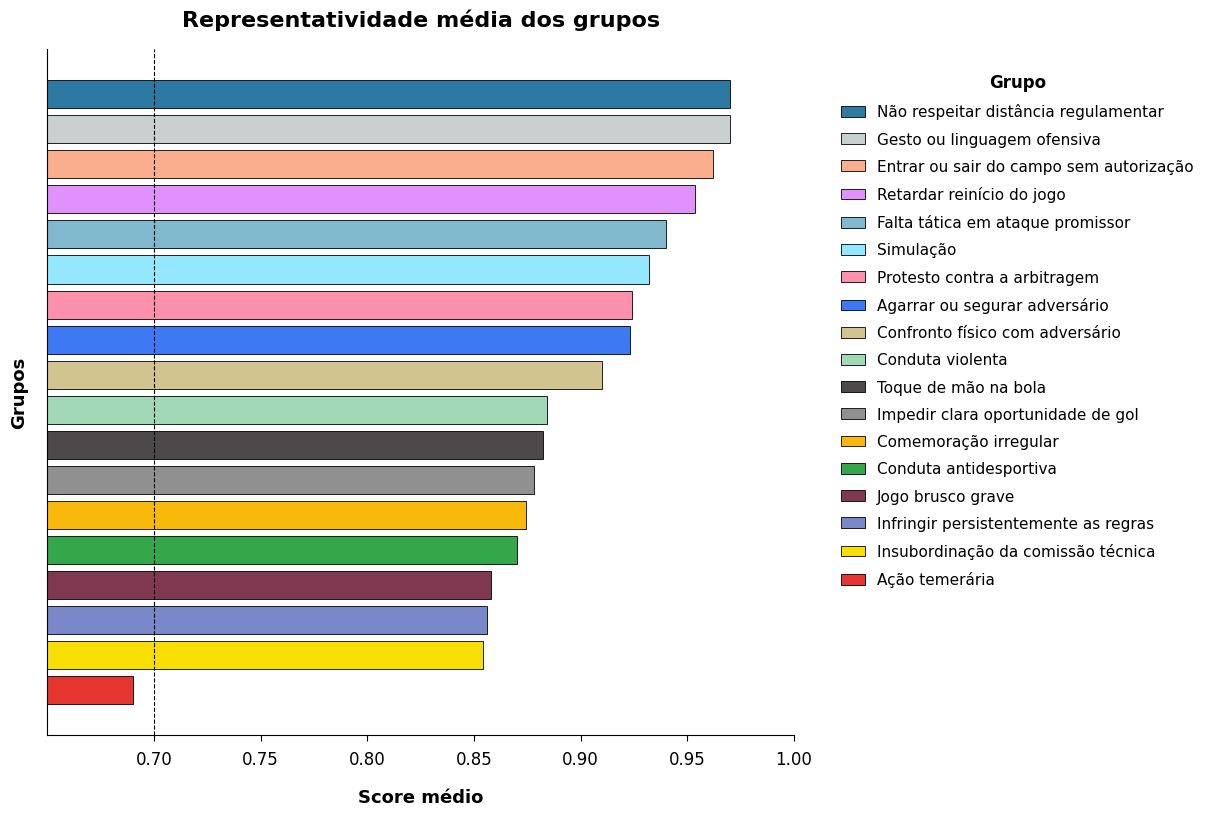

,card_reason_group,n_events,n_unique_texts,score_mean,score_p10,margin_mean,low_score_texts
1,Ação temerária,11562,2064,0.690025,0.539600,-0.001231,1319
11,Insubordinação da comissão técnica,498,330,0.854369,0.713743,-0.078975,297
10,Infringir persistentemente as regras,234,53,0.855990,0.447286,0.208412,13
12,Jogo brusco grave,301,220,0.858247,0.707783,-0.084282,220
3,Conduta antidesportiva,596,212,0.870151,0.606601,-0.036904,212
2,Comemoração irregular,455,276,0.874427,0.865133,0.062306,177
9,Impedir clara oportunidade de gol,138,101,0.878300,0.846760,-0.037201,95
17,Toque de mão na bola,194,99,0.882424,0.699076,-0.027311,79
4,Conduta violenta,176,132,0.884468,0.678165,-0.033632,132
5,Confronto físico com adversário,1002,492,0.910230,0.712665,-0.042500,492


In [25]:
representativeness_plot = card_group_quality.sort_values("score_mean", ascending=True).copy()
groups_by_score = representativeness_plot["card_reason_group"].tolist()
legend_groups_by_score = groups_by_score[::-1]
fig, ax = plt.subplots(figsize=(12.5, 8.5))
ax.barh(
    range(len(representativeness_plot)),
    representativeness_plot["score_mean"],
    color=plot_colors(groups_by_score),
    edgecolor="black",
    linewidth=0.6,
)
ax.set_yticks([])
ax.tick_params(axis="y", length=0)
ax.axvline(REPRESENTATIVENESS_MIN_SCORE, color="black", linewidth=0.8, linestyle="--")
x_min = max(0, min(representativeness_plot["score_mean"].min(), REPRESENTATIVENESS_MIN_SCORE) - 0.04)
ax.set_xlim(x_min, 1)
style_axis(ax, "Representatividade média dos grupos", "Score médio", "Grupos")
ax.legend(handles=group_legend_handles(legend_groups_by_score), title="Grupo", loc="upper left", bbox_to_anchor=(1.03, 1), frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
ax.get_legend().get_title().set_fontweight("bold")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_representativeness.png")
plt.show()

representativeness_plot[["card_reason_group", "n_events", "n_unique_texts", "score_mean", "score_p10", "margin_mean", "low_score_texts"]]

### **7.1 Conclusões da Rotulagem e Auditoria**

A taxonomia final tem 18 grupos semânticos, 102 clusters mapeados e nenhum cartão sem rótulo. Os 6.074 ajustes por âncoras lexicais corrigem casos em que um cluster denso ainda mistura termos decisivos, como força excessiva, DOGSO, simulação ou toque de mão.

Os scores de representatividade não substituem a revisão humana. Eles priorizam auditoria: grupos com margem baixa ou score menor indicam textos próximos de outra categoria e devem ser revisados primeiro nos arquivos de auditoria salvos ao final do notebook.

## **8. Resultados — Motivos de Cartão**

Cada cartão recebe `card_reason_group` a partir da taxonomia manual. A tabela `card_group_quality` resume se os textos de cada grupo são semanticamente próximos do centroide do grupo; as auditorias detalhadas ficam nos arquivos `card_reason_label_audit_*`.

### **8.1 Distribuição Geral**


In [26]:
card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
card_group_summary

,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
1,Ação temerária,11562,11486,76,2064,0.4475
14,Protesto contra a arbitragem,3925,3870,55,952,0.1519
7,Falta tática em ataque promissor,3586,3560,26,713,0.1388
15,Retardar reinício do jogo,1567,1552,15,480,0.0607
0,Agarrar ou segurar adversário,1171,1157,14,560,0.0453
5,Confronto físico com adversário,1002,951,51,492,0.0388
3,Conduta antidesportiva,596,595,1,212,0.0231
11,Insubordinação da comissão técnica,498,388,110,330,0.0193
2,Comemoração irregular,455,447,8,276,0.0176
12,Jogo brusco grave,301,96,205,220,0.0117


In [27]:
card_group_by_year = pd.crosstab(cards["year"], cards["card_reason_group"], normalize="index").round(3)
card_group_by_year

card_reason_group,Agarrar ou segurar adversário,Ação temerária,Comemoração irregular,Conduta antidesportiva,Conduta violenta,Confronto físico com adversário,Entrar ou sair do campo sem autorização,Falta tática em ataque promissor,Gesto ou linguagem ofensiva,Impedir clara oportunidade de gol,Infringir persistentemente as regras,Insubordinação da comissão técnica,Jogo brusco grave,Não respeitar distância regulamentar,Protesto contra a arbitragem,Retardar reinício do jogo,Simulação,Toque de mão na bola
year,,,,,,,,,,,,,,,,,,
2020,0.024,0.496,0.013,0.016,0.008,0.028,0.003,0.148,0.007,0.006,0.009,0.014,0.013,0.002,0.141,0.055,0.007,0.009
2021,0.033,0.506,0.015,0.016,0.007,0.033,0.002,0.121,0.006,0.005,0.009,0.017,0.011,0.002,0.154,0.047,0.005,0.011
2022,0.045,0.449,0.022,0.027,0.009,0.043,0.002,0.113,0.004,0.006,0.012,0.019,0.010,0.001,0.163,0.058,0.004,0.011
2023,0.051,0.440,0.018,0.026,0.004,0.038,0.002,0.131,0.004,0.007,0.011,0.020,0.011,0.001,0.156,0.065,0.008,0.007
2024,0.052,0.409,0.016,0.027,0.005,0.043,0.004,0.143,0.007,0.005,0.008,0.024,0.011,0.000,0.157,0.074,0.008,0.006
2025,0.054,0.413,0.019,0.022,0.007,0.046,0.004,0.166,0.004,0.003,0.007,0.022,0.014,0.001,0.147,0.062,0.007,0.004
2026,0.070,0.401,0.021,0.033,0.010,0.040,0.004,0.156,0.007,0.006,0.007,0.016,0.012,0.001,0.139,0.062,0.013,0.002


In [28]:
card_group_by_type = pd.crosstab(cards["card_type"], cards["card_reason_group"])
card_group_by_type

card_reason_group,Agarrar ou segurar adversário,Ação temerária,Comemoração irregular,Conduta antidesportiva,Conduta violenta,Confronto físico com adversário,Entrar ou sair do campo sem autorização,Falta tática em ataque promissor,Gesto ou linguagem ofensiva,Impedir clara oportunidade de gol,Infringir persistentemente as regras,Insubordinação da comissão técnica,Jogo brusco grave,Não respeitar distância regulamentar,Protesto contra a arbitragem,Retardar reinício do jogo,Simulação,Toque de mão na bola
card_type,,,,,,,,,,,,,,,,,,
red,14,76,8,1,144,51,8,26,126,93,0,110,205,0,55,15,1,4
yellow,1157,11486,447,595,32,951,66,3560,15,45,234,388,96,32,3870,1552,181,190


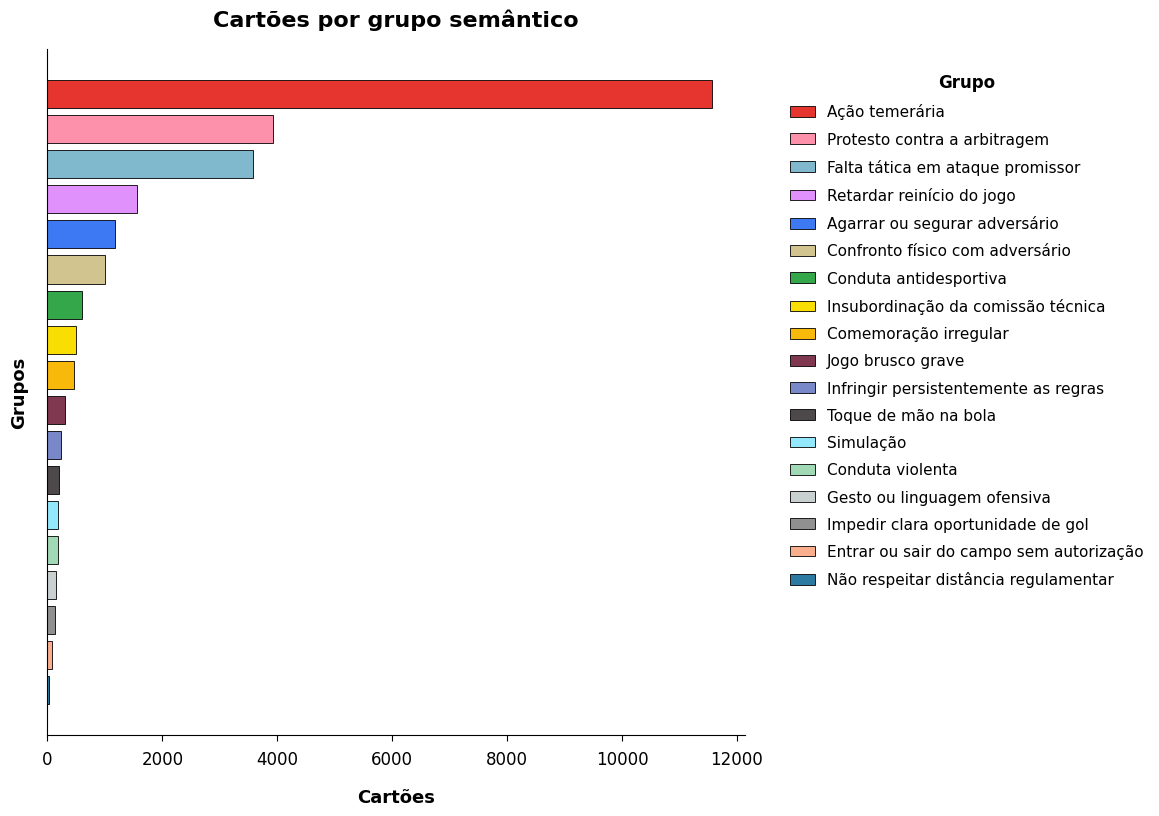

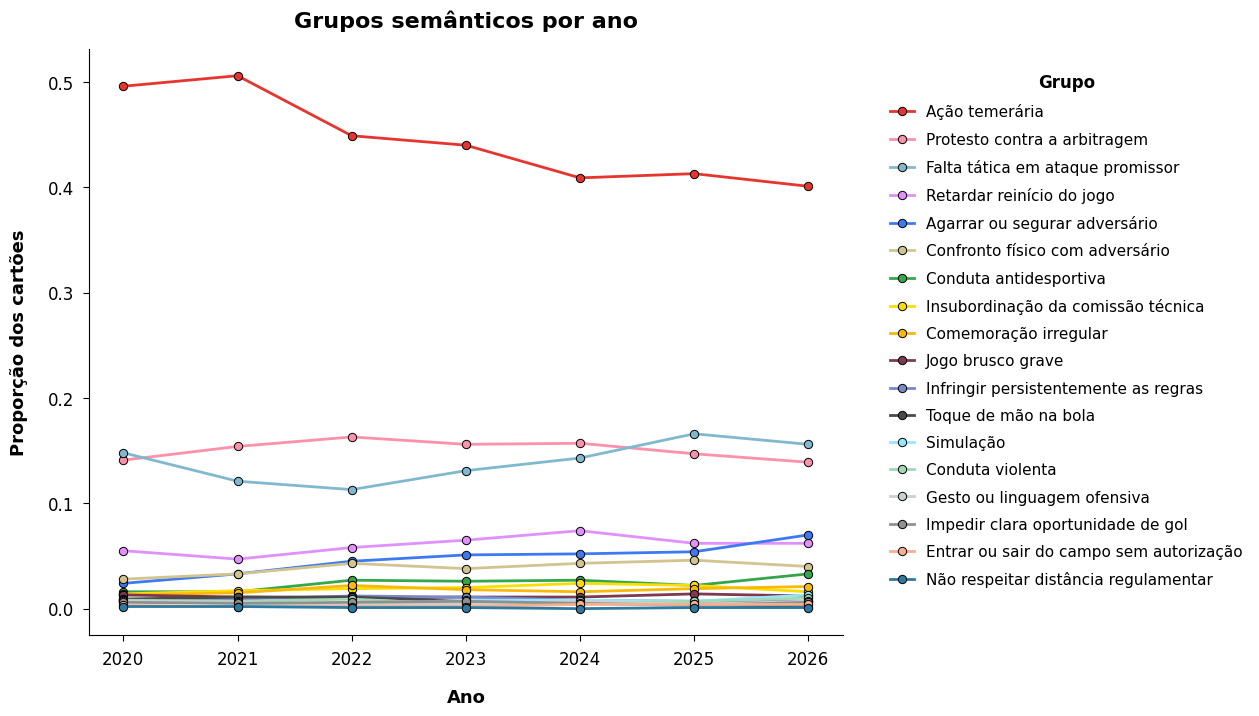

In [29]:
plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
groups_by_count = plot_card_summary["card_reason_group"].tolist()
legend_groups_by_count = groups_by_count[::-1]

fig, ax = plt.subplots(figsize=(12, 8.5))
ax.barh(
    range(len(plot_card_summary)),
    plot_card_summary["n_events"],
    color=plot_colors(groups_by_count),
    edgecolor="black",
    linewidth=0.6,
)
ax.set_yticks([])
ax.tick_params(axis="y", length=0)
style_axis(ax, "Cartões por grupo semântico", "Cartões", "Grupos")
ax.legend(handles=group_legend_handles(legend_groups_by_count), title="Grupo", loc="upper left", bbox_to_anchor=(1.03, 1), frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
ax.get_legend().get_title().set_fontweight("bold")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_counts.png")
plt.show()

all_groups = card_group_summary["card_reason_group"].tolist()
fig, ax = plt.subplots(figsize=(13, 7.5))
card_group_by_year[all_groups].plot(ax=ax, marker="o", color=plot_colors(all_groups))
style_axis(ax, "Grupos semânticos por ano", "Ano", "Proporção dos cartões")
style_lines(ax)
style_legend(ax, "Grupo", bbox_to_anchor=(1.03, 1))
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_proportions_by_year.png")
plt.show()

### **8.1.1 Interpretação da Distribuição Geral**

Os grupos mais frequentes são `Ação temerária`, `Protesto contra a arbitragem` e `Falta tática em ataque promissor`, que juntos concentram a maior parte dos eventos. Isso indica que o vocabulário das súmulas descreve principalmente faltas de disputa de bola, interrupção tática de ataques e comportamento disciplinar contra a arbitragem.

A comparação por tipo de cartão valida a coerência semântica da taxonomia: `Jogo brusco grave`, `Conduta violenta`, `Gesto ou linguagem ofensiva` e `Impedir clara oportunidade de gol` concentram proporção elevada de vermelhos, enquanto grupos como `Retardar reinício do jogo` e `Falta tática em ataque promissor` aparecem majoritariamente como amarelos.

### **8.2 Por Time**

Para cada time, a tabela detalha a contagem de cada grupo semântico nos cartões recebidos. O perfil de motivos reflete o estilo de jogo: times com proporção elevada de "Ataque promissor / falta tática" tendem a ter linha defensiva mais agressiva; times com mais "Protesto contra arbitragem" apresentam comportamento mais reativo.


In [30]:
card_reason_by_team = (
    cards.groupby(["team", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
team_card_totals = cards.groupby("team").size().rename("total_cards")
card_reason_by_team = card_reason_by_team.merge(team_card_totals, on="team", how="left")
card_reason_by_team["pct_team_cards"] = (card_reason_by_team["n_events"] / card_reason_by_team["total_cards"]).round(4)
card_reason_by_team = card_reason_by_team.sort_values(["total_cards", "team", "n_events"], ascending=[False, True, False])

card_reason_top_by_team = (
    card_reason_by_team.sort_values(["team", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("team")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_team.head(TOP_N_TEAMS)

,team,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_team_cards
0,Red Bull Bragantino,Ação temerária,491,486,5,165,1003,0.4895
1,Fluminense,Ação temerária,447,447,0,163,993,0.4502
2,Internacional,Ação temerária,420,419,1,150,955,0.4398
3,São Paulo,Ação temerária,390,387,3,144,955,0.4084
4,Palmeiras,Ação temerária,379,377,2,124,942,0.4023
5,Corinthians,Ação temerária,446,443,3,158,937,0.4760
6,Athletico Paranaense,Ação temerária,382,382,0,137,885,0.4316
7,Atlético Mineiro,Ação temerária,365,363,2,127,879,0.4152
8,Fortaleza Esporte Clube,Ação temerária,371,366,5,128,851,0.4360
9,Flamengo,Ação temerária,424,422,2,161,837,0.5066


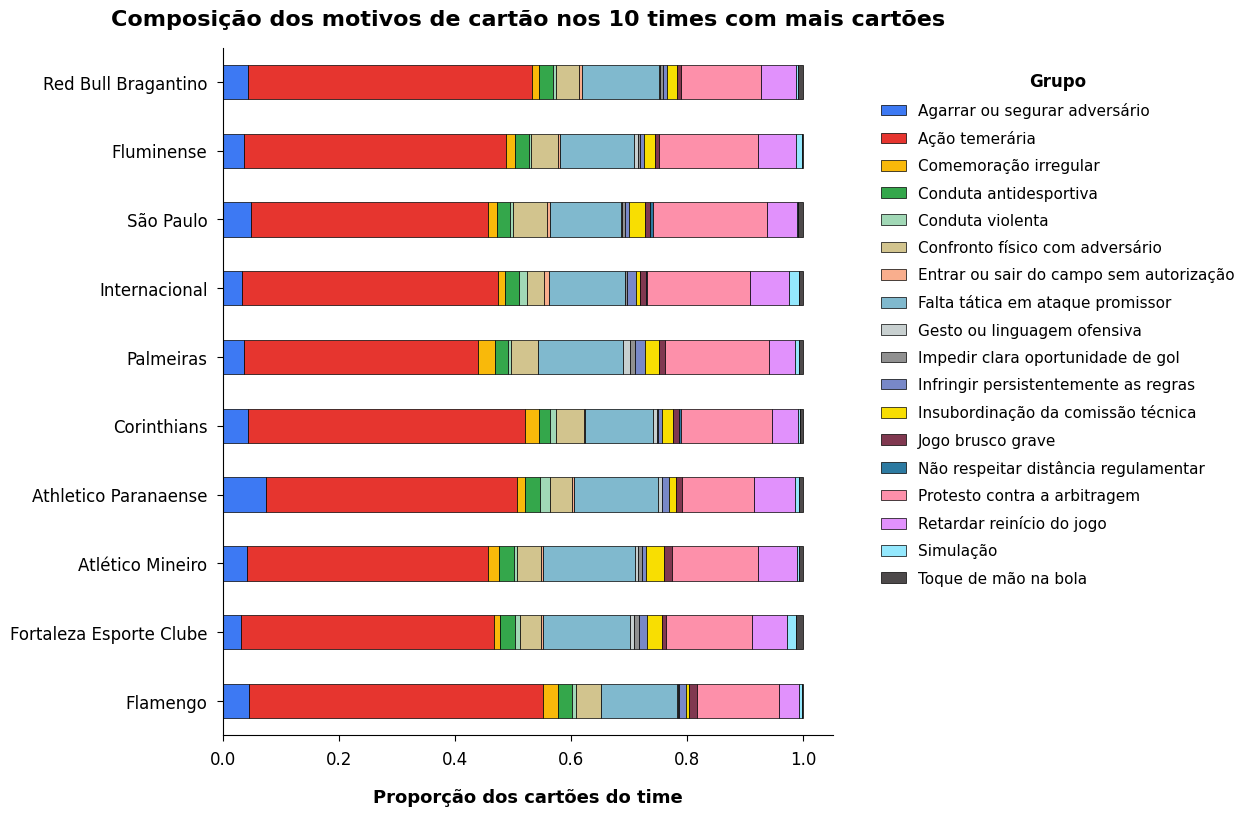

In [31]:
top_card_teams = cards["team"].value_counts().head(TOP_N_TEAMS).index
team_group_plot = pd.crosstab(
    cards.loc[cards["team"].isin(top_card_teams), "team"],
    cards.loc[cards["team"].isin(top_card_teams), "card_reason_group"],
    normalize="index",
).loc[top_card_teams]
team_group_plot = team_group_plot.reindex(columns=CARD_GROUPS, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 8.5))
team_group_plot.plot(kind="barh", stacked=True, ax=ax, color=plot_colors(team_group_plot.columns), edgecolor="black", linewidth=0.5)
ax.invert_yaxis()
style_axis(ax, f"Composição dos motivos de cartão nos {TOP_N_TEAMS} times com mais cartões", "Proporção dos cartões do time", "")
style_legend(ax, "Grupo")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_by_team.png")
plt.show()

### **8.3 Por Árbitro**

A distribuição por árbitro mostra quais tipos de infrações são mais marcados nas partidas de cada árbitro. Árbitros com proporção elevada de "Protesto contra arbitragem" tendem a ser mais rigorosos com reclamações; árbitros com mais "Falta temerária" marcam faltas mais físicas.


In [32]:
card_reason_by_referee = (
    cards.groupby(["arbitro", "arbitro_short", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
referee_card_totals = cards.groupby(["arbitro", "arbitro_short"]).size().rename("total_cards").reset_index()
card_reason_by_referee = card_reason_by_referee.merge(referee_card_totals, on=["arbitro", "arbitro_short"], how="left")
card_reason_by_referee["pct_referee_cards"] = (card_reason_by_referee["n_events"] / card_reason_by_referee["total_cards"]).round(4)
card_reason_by_referee = card_reason_by_referee.sort_values(["total_cards", "arbitro", "n_events"], ascending=[False, True, False])

card_reason_top_by_referee = (
    card_reason_by_referee.sort_values(["arbitro", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("arbitro")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_referee.head(TOP_N_REFEREES)

,arbitro,arbitro_short,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_referee_cards
0,Braulio da Silva Machado,Braulio da Silva,Ação temerária,539,539,0,111,1187,0.4541
1,Wilton Pereira Sampaio,Wilton Pereira,Ação temerária,502,494,8,155,1078,0.4657
2,Bruno Arleu de Araujo,Bruno Arleu,Ação temerária,561,561,0,179,1042,0.5384
3,Ramon Abatti Abel,Ramon Abatti,Ação temerária,437,432,5,171,993,0.4401
4,Flavio Rodrigues de Souza,Flavio Rodrigues,Ação temerária,401,398,3,132,924,0.4340
5,Raphael Claus,Raphael Claus,Ação temerária,470,468,2,144,911,0.5159
6,Anderson Daronco,Anderson Daronco,Ação temerária,416,414,2,136,909,0.4576
7,Felipe Fernandes de Lima,Felipe Fernandes,Ação temerária,351,351,0,149,851,0.4125
8,Savio Pereira Sampaio,Savio Pereira,Ação temerária,348,344,4,133,834,0.4173
9,Wagner do Nascimento Magalhaes,Wagner do Nascimento,Ação temerária,396,394,2,139,802,0.4938


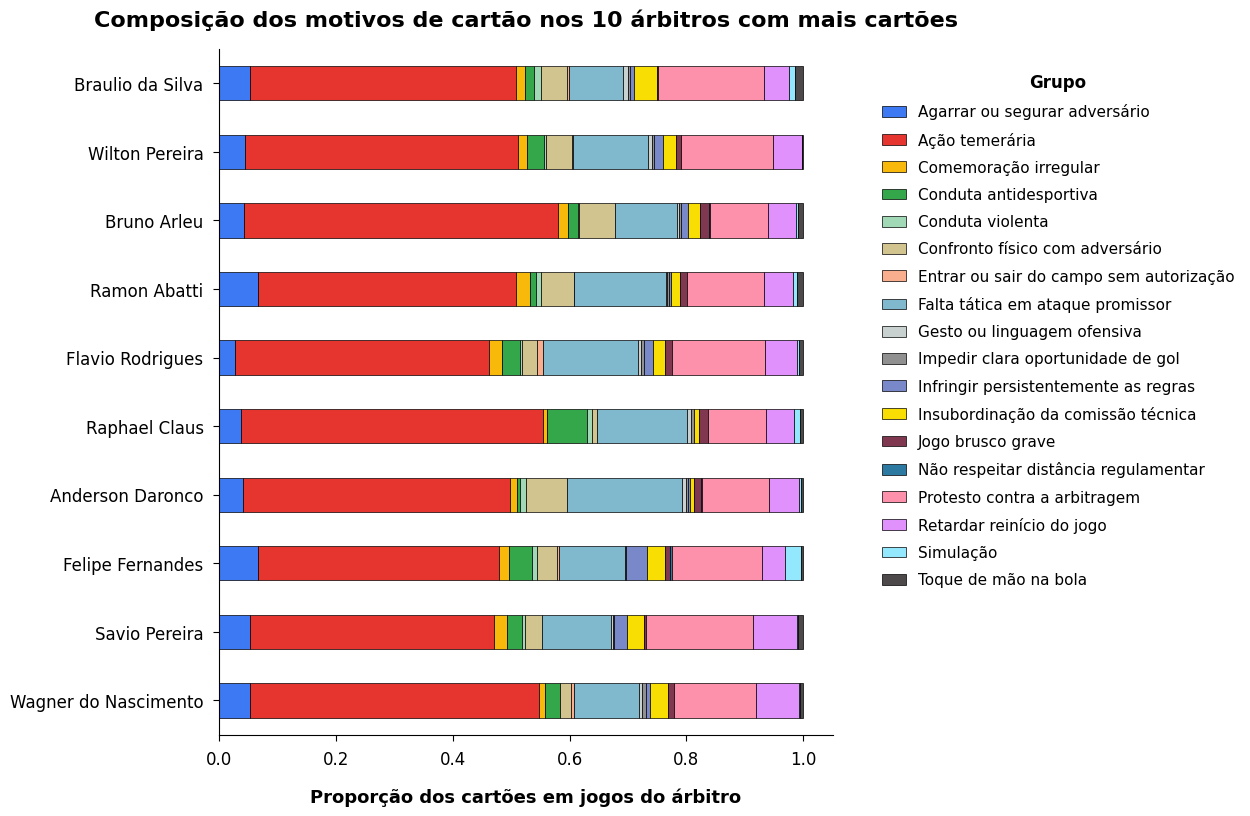

In [33]:
top_card_referees = cards["arbitro"].value_counts().head(TOP_N_REFEREES).index
referee_plot_cards = cards[cards["arbitro"].isin(top_card_referees)].copy()
referee_group_plot = pd.crosstab(
    referee_plot_cards["arbitro"],
    referee_plot_cards["card_reason_group"],
    normalize="index",
).loc[top_card_referees]
referee_group_plot = referee_group_plot.reindex(columns=CARD_GROUPS, fill_value=0)
referee_labels = cards.drop_duplicates("arbitro").set_index("arbitro").loc[top_card_referees, "arbitro_short"]
referee_group_plot.index = referee_labels

fig, ax = plt.subplots(figsize=(13, 8.5))
referee_group_plot.plot(kind="barh", stacked=True, ax=ax, color=plot_colors(referee_group_plot.columns), edgecolor="black", linewidth=0.5)
ax.invert_yaxis()
style_axis(ax, f"Composição dos motivos de cartão nos {TOP_N_REFEREES} árbitros com mais cartões", "Proporção dos cartões em jogos do árbitro", "")
style_legend(ax, "Grupo")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_by_referee.png")
plt.show()

### **8.3.1 Leitura Qualitativa por Time e Árbitro**

As tabelas por time e árbitro não devem ser lidas como ranking absoluto sem contexto de calendário, competição e número de partidas. Elas servem como diagnóstico comparativo: times com maior proporção de faltas táticas podem indicar padrão defensivo de interrupção de transições, enquanto maior presença de protestos sugere perfil disciplinar mais reativo.

Na visão por árbitro, diferenças de composição entre grupos podem refletir estilo de condução, tolerância a reclamações e perfil das partidas apitadas. Por isso, os resultados são úteis para levantar hipóteses qualitativas, não para afirmar causalidade individual sem controle adicional.

### **8.4 Busca Semântica (Diagnóstico)**

Recupera os textos mais similares a uma consulta livre no espaço de embeddings fine-tunados. Útil para auditar se expressões semanticamente equivalentes ficaram no mesmo grupo e verificar a cobertura dos protótipos.


In [34]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([ENCODE_PREFIX_QUERY + text], normalize_embeddings=True))

def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "representativeness_score",
        "representativeness_margin", "nearest_other_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)

semantic_search_cards("reclamação contra arbitragem", top_k=10)

,similarity,n_events,card_reason_group,representativeness_score,representativeness_margin,nearest_other_group,bertopic_topic,text_for_embedding
932,0.950863,4,Protesto contra a arbitragem,0.976143,0.097891,Insubordinação da comissão técnica,1,Reclamação contra a arbitragem.
4362,0.947462,1,Protesto contra a arbitragem,0.973903,0.106092,Insubordinação da comissão técnica,1,Reclamação contra a decisão da arbitragem
151,0.945248,21,Protesto contra a arbitragem,0.978373,0.092869,Insubordinação da comissão técnica,1,Por reclamação a arbitragem.
3984,0.945192,1,Protesto contra a arbitragem,0.982244,0.089480,Insubordinação da comissão técnica,1,Por reclamacao contra arbitragem.
436,0.940973,7,Protesto contra a arbitragem,0.985150,0.094492,Insubordinação da comissão técnica,1,Por reclamação contra a arbitragem.
3823,0.937890,1,Protesto contra a arbitragem,0.982873,0.090421,Insubordinação da comissão técnica,1,Por reclamar com a arbitragem.
3898,0.932609,1,Protesto contra a arbitragem,0.983546,0.086265,Insubordinação da comissão técnica,1,por reclamar das marcações da arbitragem.
4316,0.932185,1,Protesto contra a arbitragem,0.941492,0.073546,Insubordinação da comissão técnica,1,Reclamar com arbitragem.
2435,0.931488,2,Protesto contra a arbitragem,0.984627,0.090324,Insubordinação da comissão técnica,1,Por reclamar da arbitragem.
3787,0.929542,1,Protesto contra a arbitragem,0.985511,0.091988,Insubordinação da comissão técnica,1,Por reclamar conta a decisão da arbitragem.


## **9. Motivos de Acréscimos e Detecção de VAR**

Os motivos de acréscimos são tratados separadamente dos cartões. O único objetivo analítico é detectar se há menção ao VAR na justificativa de acréscimo registrada pelo árbitro.

A detecção é **léxica** — expressões regulares sobre o texto normalizado. Esta abordagem é suficiente porque a presença de VAR é um sinal fortemente textual: árbitros mencionam explicitamente "VAR", "AVAR", "revisão de vídeo" etc. quando o protocolo é ativado.

### **9.1 Exploração dos Textos de Atraso (BERTopic)**

BERTopic aplicado ao corpus de textos de atraso para mapear a diversidade temática. Esta etapa é exploratória — os clusters não são usados na detecção de VAR.


In [35]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)

,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,31,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
4,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [36]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in delay_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")

Batches:   0%|          | 0/60 [00:00<?, ?it/s]

Batches: 100%|██████████| 60/60 [01:04<00:00,  1.08s/it]

Embeddings de atrasos/acréscimos: (3780, 1024)


In [37]:
delay_topic_model = make_topic_model(DELAY_MIN_TOPIC_SIZE)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)

,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,879,0_substituições_acréscimos_atendimento_atletas,"[substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições, substituições atendimento, retirada]","[Acréscimos devido substituições, atendimento médico a atletas supostamente lesionados e reposição de bola., Acréscimos devido a substituições e atendimento de atletas supostamente lesionados ., Acréscimos devido as ...",879,1458,"substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições"
1,1,440,1_homenagem_silêncio_respeitado_silêncio homenagem,"[homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, acréscimos, respeitado silêncio, substituições, respeitado silêncio homenagem]","[Acréscimos devido a substituições e atendimento de atletas supostamente lesionados.foi respeitado 1 minuto de silêncio em homenagem as vitimas da covid 19., Acréscimos devido a substituições, retirada de atletas sup...",440,641,"homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, acréscimos, respeitado silêncio"
2,-1,389,-1_atraso_ilustre_fluminense_torcedor,"[atraso, ilustre, fluminense, torcedor, flamengo, substituições, acréscimos, lesionados, atletas, informo]","[Não houve atrasos no início e renício da partida.foram acrescidos 2 e 4 minutos no primeiro e segundo tempo respectivamente, devido a atendimento a atletas supostamente lesionados, reposição de bola em jogo e substi...",389,559,outliers
3,2,372,2_não_não houve_houve_não houve atraso,"[não, não houve, houve, não houve atraso, houve atraso, acréscimos, atrasos, substituições, atrasos acréscimos, houve atraso acréscimos]","[Não houve atrasos. acréscimos devido a substituições e retirada de atletas supostamente lesionados do campo de jogo., Não houve atraso. acréscimos por substituições e retirada de atletas supostamente lesionados., Nã...",372,544,"não, não houve, houve, não houve atraso, houve atraso, acréscimos, atrasos, substituições"
4,3,282,3_não houve_não_houve_homenagem,"[não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma, homenagem póstuma, respeitado]","[Não houve atrasos. acréscimos devido as substituições, retirada de atletas supostamente lesionados e reposição de bola.informo que antes da partida foi respeitado um minuto de silêncio em homenagem póstuma as vitima...",282,451,"não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma"
5,4,259,4_homenagem_silêncio_respeitado_covid,"[homenagem, silêncio, respeitado, covid, 19, covid 19, silêncio homenagem, acréscimos, substituições, 19 acréscimos]","[Foi respeitado 1 minuto de silêncio em homenagem as vitimas da covid 19.acréscimos devido a substituições e atendimento de atletas supostamente lesionados., Foi respeitado 1 minuto de silêncio de homenagem as vítima...",259,346,"homenagem, silêncio, respeitado, covid, 19, covid 19, silêncio homenagem, acréscimos"
6,5,234,5_atraso_entrada_reinício_equipes,"[atraso, entrada, reinício, equipes, informo, acréscimos, substituições, ambas, segundo, ambas equipes]","[Houve atraso no inicio da partida de 02 minutos devido ao atraso de ambas as equipes.acréscimos devido atendimento a atletas supostamente lesionados, reposição de bola e substituições., Informo que ambas as equipes ...",234,304,"atraso, entrada, reinício, equipes, informo, acréscimos, substituições, ambas"
7,6,189,6_primeiro_segundo_primeiro segundo_acréscimos primeiro,"[primeiro, segundo, primeiro segundo, acréscimos primeiro, substituições, segundo paralisações substituições, segundo paralisações, lesionados, atendimento, segundo substituições]","[Acréscimos de 2 minutos no primeiro tempo, e 4 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var., Acréscimos de 6 minutos no pr

In [38]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)

,bertopic_topic,n_games,text_for_embedding
0,-1,2,- ACRESCIMOS DEVIDO SUBSTITUIÇÕES E RETIRADA DE ATLETAS DO CAMPO.- CONCEDIDO UM MINUTO DE SILENCIO EM HOMENAGEM POSTUMA AS VITIMAS DA COVID19 E O SR. JOSÉ WILSON SALES JUNIOR.- INFORMO QUE NAO CONSEGUIMOS INSERIR O D...
1,-1,2,Acréscimos devido substituições e paralisações diversas. atraso no reinício de partida devido horário de entrada em campo da equipe mandante.
2,-1,2,Acrescimos devido substituições e retirada de atletas do campo de jogo. foi concedido um minuto de silencio em homenagem postumas a diego armando maradona e as vitimas da covid 19.
3,-1,2,"Acréscimos devido substituições de ambas as equipes, comemorações de gols e checagem var. homenagem póstuma no jogo flamengo x fluminense para os seguintes nomes: 1. alessandro vinicius neves de lima - ilustre torced..."
4,-1,2,* acrescimos devido substituições e retirada de atletas do campo de jogo.* concedido um minuto de silencio em homenagem postuma as vitimas da covid19.
5,0,31,Acréscimos devido as substituições e atendimento médico aos atletas.
6,0,22,Acréscimos devido substituições e transporte de atletas lesionados.
7,0,14,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo."
8,0,13,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas."
9,0,13,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .


### **9.1.1 Conclusões da Exploração dos Textos de Atraso**

Os tópicos de atraso/acréscimos capturam motivos recorrentes como substituições, atendimento médico, reposição de bola e checagens. Como o objetivo desta parte é detectar menção a VAR, os clusters do BERTopic são usados apenas para entender o vocabulário e verificar se há grupos textuais coerentes; a decisão final usa regras léxicas transparentes.

### **9.2 Detecção Léxica de VAR**

Os padrões cobrem siglas institucionais (`VAR`, `AVAR`, `VOR`, `ARA`), variações descritivas (`árbitro de vídeo`), termos de processo (`checagem`, `revisão`, `review`) e referências a infraestrutura (`monitor`, `cabine`). O sinal `monitor_cabine` é o mais ambíguo — "monitor" pode aparecer em contextos não-VAR.


In [39]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"\bmonitor\b|\bcabine\b",
}

def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)

var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary

games_total              5681.0000
games_with_var_signal    2035.0000
pct_with_var_signal         0.3582
dtype: float64

In [40]:
signal_counts = {}
for signal_name, pattern in VAR_SIGNAL_PATTERNS.items():
    signal_counts[signal_name] = delays[DELAY_TEXT_COLUMN].apply(
        lambda t, p=pattern: bool(re.search(p, normalize_text(str(t))))
    ).sum()

signal_dist = pd.Series(signal_counts, name='partidas').sort_values(ascending=False)
print('Frequência de cada sinal VAR:')
print(signal_dist.to_string())

only_monitor = (
    delays[delays['var_signal'].eq('monitor_cabine')]
    [[DELAY_TEXT_COLUMN, 'year']]
    .drop_duplicates(DELAY_TEXT_COLUMN)
    .sort_values('year')
    .reset_index(drop=True)
)
print(f'\nTextos ativados exclusivamente por monitor_cabine: {len(only_monitor)}')
print('Revisar manualmente para estimar precisão do detector neste sinal.')
only_monitor.head(10)

Frequência de cada sinal VAR:
var                 1749
checagem            1514
revisao              563
ara                  136
arbitro_de_video      79
vor                   48
monitor_cabine        36
avar                   2

Textos ativados exclusivamente por monitor_cabine: 1
Revisar manualmente para estimar precisão do detector neste sinal.


,delay_reason_clean,year
0,"Não houve atraso. os acréscimos foram dados por reposição da bola em jogo, gols, substituições atendimento ao goleiro mandante, tempo de cabine e retirada de atletas para atendimento.",2023


### **9.2.1 Conclusões da Detecção de VAR**

Foram detectados sinais de VAR em 2.031 de 5.663 partidas, equivalentes a 35,86% da base. Os sinais mais frequentes são `var` e `checagem`, o que confirma que a regra captura termos explícitos do protocolo.

O padrão `monitor_cabine` é tratado como ambíguo. A saída mostra apenas um texto ativado exclusivamente por esse sinal, então ele é mantido como ponto de auditoria manual sem dominar o resultado agregado.

### **9.3 Evolução do VAR por Ano**

Proporção de partidas com sinal de VAR detectado por ano. Espera-se crescimento após a implementação do sistema no Campeonato Brasileiro a partir de 2019.


In [41]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year

,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,391,111,0.2839


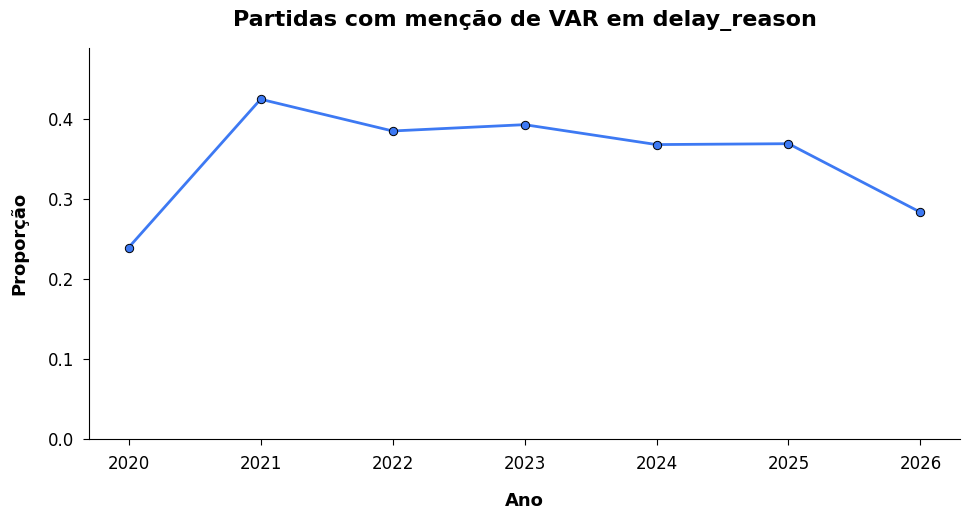

In [42]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    delay_var_by_year["year"],
    delay_var_by_year["pct_with_var_signal"],
    marker="o",
    color=PLOT_BLUE,
    markerfacecolor=PLOT_BLUE,
    markeredgecolor="black",
    markeredgewidth=0.7,
)
style_axis(ax, "Partidas com menção de VAR em delay_reason", "Ano", "Proporção")
style_lines(ax)
ax.set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))
plt.tight_layout(pad=1.5)
save_plot(fig, "var_mentions_by_year.png")
plt.show()

### **9.3.1 Interpretação Temporal do VAR**

A proporção de partidas com sinal textual de VAR cresce de 23,98% em 2020 para patamares próximos de 37% a 43% entre 2021 e 2025. Essa estabilização sugere maior presença de registros explícitos de checagem/revisão nas súmulas após 2020.

O valor de 2026 aparece menor porque a coleta daquele ano ainda é parcial. Por isso, a leitura temporal deve comparar principalmente temporadas completas.

In [43]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro_short", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples

,year,round,home_team,away_team,arbitro_short,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


### **9.4 VAR por Time e Árbitro**

Para times: contagem sobre partidas em que o time aparece como mandante ou visitante — o mesmo jogo é contado para ambos. Para árbitros: contagem sobre as partidas apitadas. Em ambos os casos, `var_used` indica presença de sinal textual de VAR no campo de atraso, não validação externa do protocolo.


In [44]:
def most_common_non_empty(values: pd.Series) -> str:
    cleaned = values.astype(str).str.strip()
    cleaned = cleaned[cleaned.ne("")]
    if cleaned.empty:
        return ""
    return cleaned.value_counts().idxmax()

delay_home_games = delays.rename(columns={"home_team": "team", "away_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "arbitro_short", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_away_games = delays.rename(columns={"away_team": "team", "home_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "arbitro_short", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_team_games = pd.concat([delay_home_games, delay_away_games], ignore_index=True)

delay_var_by_team = (
    delay_team_games.groupby("team")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_team["pct_with_var_signal"] = (
    delay_var_by_team["games_with_var_signal"] / delay_var_by_team["games"]
).round(4)
delay_var_by_team = delay_var_by_team.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_team.head(TOP_N_TEAMS)

,team,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Red Bull Bragantino,457,175,"var, checagem",0.3829
1,Flamengo,444,189,"var, checagem",0.4257
2,Corinthians,443,194,"var, checagem",0.4379
3,Fluminense,443,174,"var, checagem",0.3928
4,Palmeiras,427,196,"var, checagem",0.4590
5,Internacional,418,177,"var, checagem",0.4234
6,Athletico Paranaense,399,170,"var, checagem",0.4261
7,São Paulo,397,207,"var, checagem",0.5214
8,Atlético Mineiro,397,146,"var, checagem",0.3678
9,Fortaleza Esporte Clube,368,158,"var, checagem",0.4293


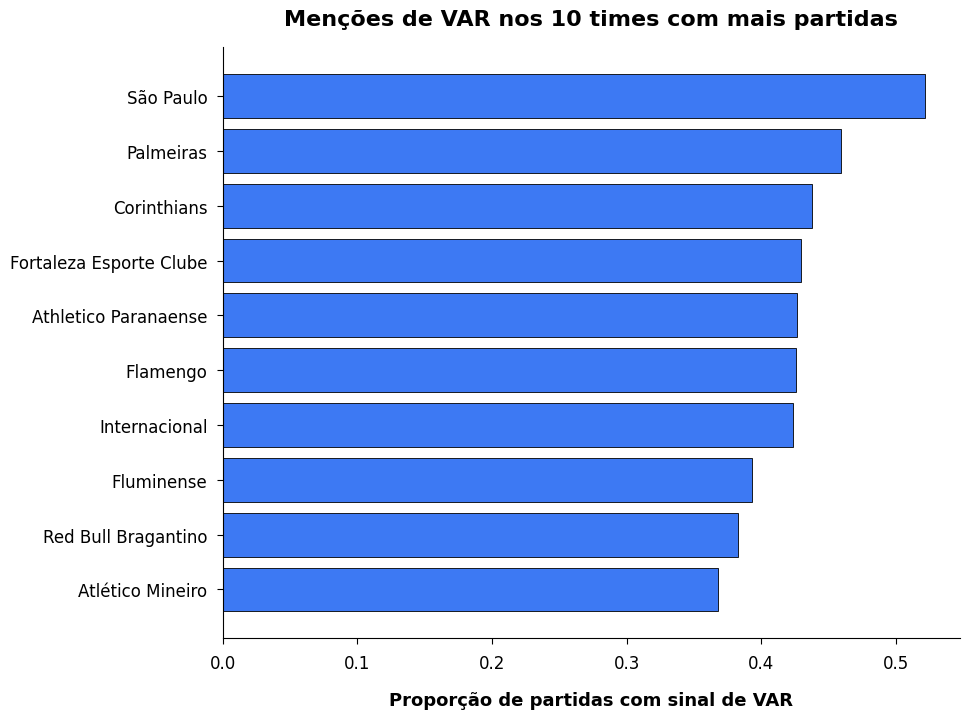

In [45]:
top_var_teams = delay_var_by_team.head(TOP_N_TEAMS).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(top_var_teams["team"], top_var_teams["pct_with_var_signal"], color=PLOT_BLUE, edgecolor="black", linewidth=0.6)
style_axis(ax, f"Menções de VAR nos {TOP_N_TEAMS} times com mais partidas", "Proporção de partidas com sinal de VAR", "")
plt.tight_layout(pad=1.5)
save_plot(fig, "var_mentions_by_team.png")
plt.show()

In [46]:
delay_var_by_referee = (
    delays.groupby(["arbitro", "arbitro_short"])
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_referee["pct_with_var_signal"] = (
    delay_var_by_referee["games_with_var_signal"] / delay_var_by_referee["games"]
).round(4)
delay_var_by_referee = delay_var_by_referee.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_referee.head(TOP_N_REFEREES)

,arbitro,arbitro_short,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Anderson Daronco,Anderson Daronco,255,83,"var, checagem",0.3255
1,Raphael Claus,Raphael Claus,243,80,"var, checagem",0.3292
2,Ramon Abatti Abel,Ramon Abatti,233,102,"var, checagem",0.4378
3,Braulio da Silva Machado,Braulio da Silva,223,132,"var, checagem",0.5919
4,Wilton Pereira Sampaio,Wilton Pereira,223,103,"var, checagem",0.4619
5,Flavio Rodrigues de Souza,Flavio Rodrigues,218,95,"var, checagem",0.4358
6,Bruno Arleu de Araujo,Bruno Arleu,206,87,"var, checagem",0.4223
7,Savio Pereira Sampaio,Savio Pereira,191,81,"var, checagem",0.4241
8,Marcelo de Lima Henrique,Marcelo de Lima,175,67,"var, checagem",0.3829
9,Wagner do Nascimento Magalhaes,Wagner do Nascimento,166,59,"var, checagem",0.3554


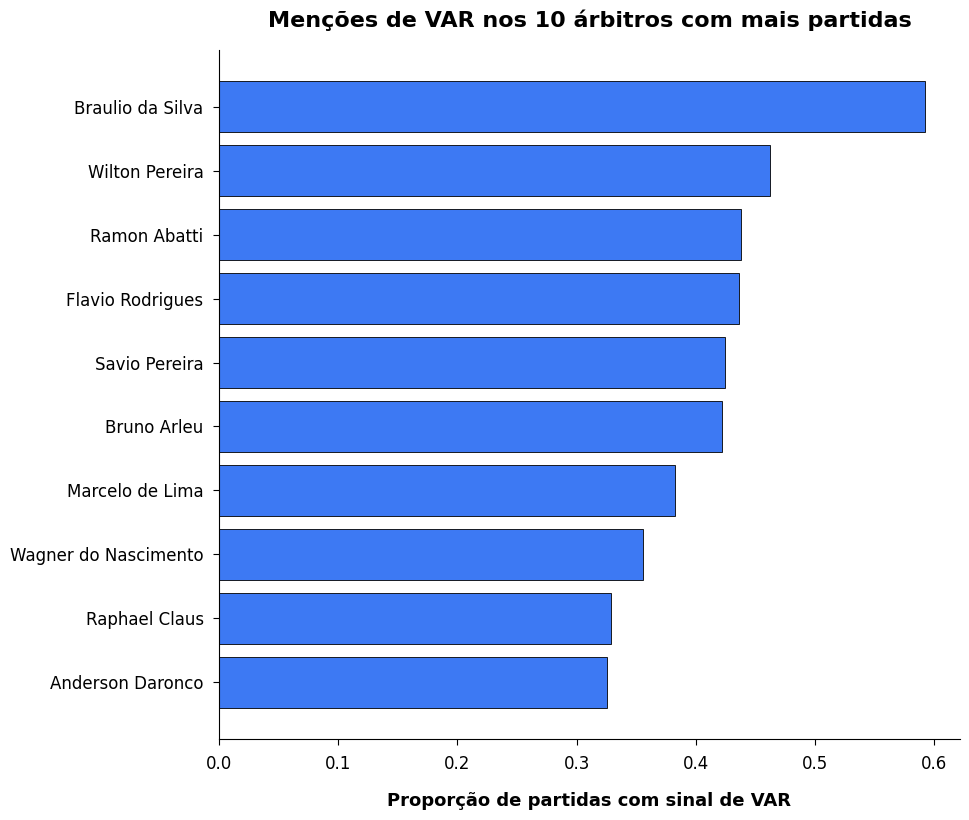

In [47]:
top_var_referees = delay_var_by_referee.head(TOP_N_REFEREES).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 8.5))
ax.barh(top_var_referees["arbitro_short"], top_var_referees["pct_with_var_signal"], color=PLOT_BLUE, edgecolor="black", linewidth=0.6)
style_axis(ax, f"Menções de VAR nos {TOP_N_REFEREES} árbitros com mais partidas", "Proporção de partidas com sinal de VAR", "")
plt.tight_layout(pad=1.5)
save_plot(fig, "var_mentions_by_referee.png")
plt.show()

### **9.4.1 Interpretação por Time e Árbitro**

Entre os times com mais jogos na base, as proporções de sinal de VAR variam de cerca de 37% a 52%, com `var` e `checagem` como sinais dominantes. Entre árbitros, a variação também é relevante, mas pode refletir combinação de ano, competição, perfil das partidas e forma de redação da súmula.

Esses recortes funcionam como análise qualitativa de padrões textuais. Eles indicam onde investigar diferenças de registro do VAR, mas não medem diretamente quantidade de revisões oficiais confirmadas.

## **10. Salvamento dos Artefatos**

Arquivos gerados em `data/processed/semantic_reasons/card_reasons/`:

- `card_reasons_with_labels.csv` — dataset completo com grupo semântico por cartão
- `card_reason_group_summary.csv` — distribuição de eventos por grupo
- `card_reason_group_quality.csv` — score médio, p10 e margem por grupo
- `card_reason_label_audit_terms.csv` — auditoria por texto único
- `card_reason_label_audit_clusters.csv` — auditoria por cluster BERTopic
- `card_reason_label_audit_outliers.csv` — auditoria dos outliers HDBSCAN

Arquivos gerados em `data/processed/semantic_reasons/delay_reasons/` mantêm a análise de VAR.


In [48]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)

card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_quality_path = CARD_OUTPUT_DIR / "card_reason_group_quality.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
card_reason_by_team_path = CARD_OUTPUT_DIR / "card_reason_by_team.csv"
card_reason_top_by_team_path = CARD_OUTPUT_DIR / "card_reason_top_by_team.csv"
card_reason_by_referee_path = CARD_OUTPUT_DIR / "card_reason_by_referee.csv"
card_reason_top_by_referee_path = CARD_OUTPUT_DIR / "card_reason_top_by_referee.csv"
card_label_audit_terms_path = CARD_OUTPUT_DIR / "card_reason_label_audit_terms.csv"
card_label_audit_clusters_path = CARD_OUTPUT_DIR / "card_reason_label_audit_clusters.csv"
card_label_audit_outliers_path = CARD_OUTPUT_DIR / "card_reason_label_audit_outliers.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"
delay_var_by_team_path = DELAY_OUTPUT_DIR / "delay_var_by_team.csv"
delay_var_by_referee_path = DELAY_OUTPUT_DIR / "delay_var_by_referee.csv"

card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_quality.to_csv(card_group_quality_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
card_reason_by_team.to_csv(card_reason_by_team_path, index=False)
card_reason_top_by_team.to_csv(card_reason_top_by_team_path, index=False)
card_reason_by_referee.to_csv(card_reason_by_referee_path, index=False)
card_reason_top_by_referee.to_csv(card_reason_top_by_referee_path, index=False)
card_reason_label_audit_terms.to_csv(card_label_audit_terms_path, index=False)
card_reason_label_audit_clusters.to_csv(card_label_audit_clusters_path, index=False)
card_reason_label_audit_outliers.to_csv(card_label_audit_outliers_path, index=False)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)
delay_var_by_team.to_csv(delay_var_by_team_path, index=False)
delay_var_by_referee.to_csv(delay_var_by_referee_path, index=False)

output_paths = [
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_quality_path,
    card_group_by_year_path,
    card_group_by_type_path,
    card_reason_by_team_path,
    card_reason_top_by_team_path,
    card_reason_by_referee_path,
    card_reason_top_by_referee_path,
    card_label_audit_terms_path,
    card_label_audit_clusters_path,
    card_label_audit_outliers_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
    delay_var_by_team_path,
    delay_var_by_referee_path,
]

print("Arquivos salvos:")
for output_path in output_paths:
    print(f"  {output_path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_quality.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_year.csv
  /Users/gcarninatto/Docume